# Job Offers Analysis in the Data Field using NLP and Machine Learning

**Advanced Learning project — S3: *Analyse des offres d'emploi en Data***

This notebook is the full, reproducible pipeline of the project. Run it top to bottom: it cleans the dataset, trains and evaluates every model, and writes all artifacts to `models/`, `data/processed/` and `results/`. The Flask application (`python run.py`) loads those artifacts and never retrains anything.

## 1. Introduction and objectives

| # | Objective | Technique used here |
|---|---|---|
| 1 | Analyse data-job advertisements | Pandas exploration and EDA on 785k postings |
| 2 | Extract technical skills and entities | Skill gazetteer, alias normalisation, regex phrase matching, ambiguity rules; DistilBERT skill embeddings |
| 3 | Classify ads into `job_title_short` | **TF-IDF + Logistic Regression** (scikit-learn `Pipeline`) |
| 4 | Semantic representations and similarity | **DistilBERT** mean-pooled embeddings + cosine similarity |
| 5 | Group similar ads, discover professions | **K-Means** on DistilBERT embeddings (elbow + silhouette) |
| 6 | Relations between skills, jobs and companies | **Knowledge graph** (NetworkX), Louvain communities, Personalised PageRank, mini graph Q&A |
| 7 | Interactive exploration | Flask web application (`app/`) |

**Important property of the dataset.** `lukebarousse/data_jobs` does **not** publish the full job-description text. Each posting has a raw title (`job_title`), a standardised category (`job_title_short`), company, location, salary fields and a list of skills (`job_skills`) that the dataset author extracted from the original descriptions. All text models therefore work on a document built from **title + skills**. Section 9 explains how this affects the classification results.

## 2. Library imports and configuration

Core model code (tokenizer, DistilBERT, skill extractor, knowledge graph) lives in the `jobnlp/` package at the project root. The notebook and the Flask app share it, so preprocessing at training time and at prediction time is the same code, with no duplication.

In [1]:
import sys, json, time, random, warnings, subprocess, platform
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from jobnlp.skills import SkillExtractor, SKILL_CATEGORIES
from jobnlp.preprocessing import (find_raw_dataset, clean_dataset, skill_analyzer, clean_for_tfidf,
                                  TARGET, KEEP_COLUMNS)
from jobnlp.distilbert import DistilBertEncoder
from jobnlp.embeddings import (sample_for_embedding, compute_or_load_embeddings, center_normalize,
                               top_k_cosine)
from jobnlp.graph import build_posting_index, KnowledgeGraph
from jobnlp import viz

SEED = 42
random.seed(SEED); np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROC = PROJECT_ROOT / "data" / "processed"
MODELS = PROJECT_ROOT / "models"
FIG = PROJECT_ROOT / "results" / "figures"
METRICS = PROJECT_ROOT / "results" / "metrics"
for d in (DATA_RAW, DATA_PROC, MODELS, FIG, METRICS):
    d.mkdir(parents=True, exist_ok=True)

# DistilBERT checkpoint files (config.json, vocab.txt, model.safetensors) from
# https://huggingface.co/distilbert-base-uncased
BERT_DIR = MODELS / "distilbert-base-uncased"
if not (BERT_DIR / "model.safetensors").exists() and (PROJECT_ROOT / "model.safetensors").exists():
    BERT_DIR = PROJECT_ROOT          # files left at the project root
RECOMPUTE_EMBEDDINGS = False          # True forces DistilBERT to re-embed the corpus

viz.apply_style()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__}")
print("Project root:", PROJECT_ROOT)

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1
Project root: /home/claude/work


## 3. Dataset loading

Source: [Hugging Face — lukebarousse/data_jobs](https://huggingface.co/datasets/lukebarousse/data_jobs), a scrape of Google Jobs postings for data roles from 2023. The loader uses the local copy (`data/raw/data_jobs.csv`, or `data_jobs.csv` at the project root).

In [2]:
try:
    RAW_PATH = find_raw_dataset(PROJECT_ROOT)
except FileNotFoundError as e:
    raise SystemExit(str(e))
t0 = time.time()
raw = pd.read_csv(RAW_PATH, low_memory=False)
print(f"Loaded {RAW_PATH.relative_to(PROJECT_ROOT)}: {raw.shape[0]:,} rows x {raw.shape[1]} columns "
      f"in {time.time()-t0:.1f}s")
display(raw.head(3).T)

Loaded data/raw/data_jobs.csv: 785,741 rows x 17 columns in 3.9s


,0,1,2
job_title_short,Senior Data Engineer,Data Analyst,Data Engineer
job_title,Senior Clinical Data Engineer / Principal Clin...,Data Analyst,"Data Engineer/Scientist/Analyst, Mid or Senior..."
job_location,"Watertown, CT","Guadalajara, Jalisco, Mexico","Berlin, Germany"
job_via,via Work Nearby,via BeBee México,via LinkedIn
job_schedule_type,Full-time,Full-time,Full-time
job_work_from_home,False,False,False
search_location,"Texas, United States",Mexico,Germany
job_posted_date,2023-06-16 13:44:15,2023-01-14 13:18:07,2023-10-10 13:14:55
job_no_degree_mention,False,False,False
job_health_insurance,False,False,False


## 4. Dataset exploration and schema analysis

In [3]:
schema = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
    "n_unique": raw.nunique(),
    "example": [raw[c].dropna().iloc[0] if raw[c].notna().any() else None for c in raw.columns],
})
display(schema)
print(f"Exact duplicate rows: {raw.duplicated().sum():,}")
print(f"Duplicate (title, company, location, skills): "
      f"{raw.duplicated(subset=['job_title','company_name','job_location','job_skills']).sum():,}")
print(f"Classes in {TARGET}: {raw[TARGET].nunique()}")

,dtype,non_null,missing_%,n_unique,example
job_title_short,str,785741,0.00,10,Senior Data Engineer
job_title,str,785740,0.00,234673,Senior Clinical Data Engineer / Principal Clin...
job_location,str,784696,0.13,17217,"Watertown, CT"
job_via,str,785733,0.00,7903,via Work Nearby
job_schedule_type,str,773074,1.61,47,Full-time
job_work_from_home,bool,785741,0.00,2,False
search_location,str,785741,0.00,173,"Texas, United States"
job_posted_date,str,785741,0.00,607192,2023-06-16 13:44:15
job_no_degree_mention,bool,785741,0.00,2,False
job_health_insurance,bool,785741,0.00,2,False


Exact duplicate rows: 101
Duplicate (title, company, location, skills): 117,738
Classes in job_title_short: 10


**Schema findings**

* There are 17 columns. `job_title_short` (10 classes) is the classification target. According to the dataset card, the author derived it from `job_title` with a BERT classifier.
* `job_skills` is a *stringified Python list*, and `job_type_skills` is the same skills grouped by type in a stringified dict. Both are missing for **14.9 %** of rows.
* Salary is very sparse: `salary_year_avg` is missing for 97 % of rows. It is used only for descriptive statistics and is never a model input.
* Exact duplicates are rare (101 rows). The real duplication problem is the **same ad re-posted on several platforms** (`job_via`), which would put copies of one ad in both the training and the test set.

## 5. Data cleaning and preprocessing

| Step | Decision | Justification |
|---|---|---|
| Keep 14 useful columns | drop `search_location`, `salary_rate`, `job_type_skills` | `job_type_skills` duplicates `job_skills`; the other two are scraping metadata |
| Remove exact duplicates | `drop_duplicates()` | identical rows add no information |
| Text normalisation | Unicode NFKC, unified dashes and quotes, collapsed whitespace, `via ` prefix removed | consistent tokens |
| Parse `job_skills` | `ast.literal_eval`, then canonical skill names through the skill dictionary | e.g. `powerbi` → `power bi`, `mongo` → `mongodb` |
| Missing values | drop the 15 % of postings **without skills**; fill `Unknown` in location, country and schedule | without skills the document is just a title, which is useless for skill analysis and clustering; the categorical gaps are tiny |
| **Leakage control** | remove cross-platform re-posts: same (title, company, location, skills) | stops copies of one ad landing in both train and test, which would inflate the test scores |
| Text views | `text_tfidf` (cleaned lower-case title + skills) for TF-IDF; `text_embed` (natural sentence) for DistilBERT | each model gets the input format that suits it |

In [4]:
extractor = SkillExtractor()
df, clean_report = clean_dataset(raw, extractor)
display(pd.DataFrame.from_dict(clean_report, orient="index", columns=["rows"]))
display(df[["job_title_short", "job_title", "company_name", "job_country", "skills", "text_tfidf",
            "text_embed"]].head(5))

# portable processed dataset (CSV, skills joined by '|') - no pickle, so it loads with any pandas version
PROC_COLS = ["job_id", "job_title_short", "job_title", "company_name", "job_location", "job_country",
             "job_via", "job_schedule_type", "job_work_from_home", "job_posted_date", "salary_year_avg",
             "skills_str"]
df[PROC_COLS].to_csv(DATA_PROC / "jobs_clean.csv.gz", index=False, compression="gzip")
print("Saved", (DATA_PROC / "jobs_clean.csv.gz").relative_to(PROJECT_ROOT),
      f"({(DATA_PROC / 'jobs_clean.csv.gz').stat().st_size/1e6:.1f} MB)")
del raw

,rows
raw_rows,785741
exact_duplicates_removed,101
rows_without_skills,116986
rows_after_dropping_no_skills,668654
cross_platform_duplicates_removed,103995
final_rows,564659


,job_title_short,job_title,company_name,job_country,skills,text_tfidf,text_embed
0,Data Analyst,Data Analyst,Hewlett Packard Enterprise,Mexico,"[nosql, power bi, python, r, sql, tableau]",data analyst skills nosql power bi python r sq...,"Data Analyst. Skills: nosql, power bi, python,..."
1,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...",ALPHA Augmented Services,Germany,"[airflow, azure, c#, dax, docker, jenkins, kub...",data engineer/scientist/analyst mid or senior ...,"Data Engineer/Scientist/Analyst, Mid or Senior..."
2,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,Southwest Research Institute,United States,"[aws, c++, java, keras, matlab, python, pytorc...",lead engineer principal analyst principal engi...,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...
3,Data Engineer,Data Engineer- Sr Jobs,Kristina Daniel,Sudan,"[ansible, aws, bash, git, gitlab, jenkins, ora...",data engineer sr jobs skills ansible aws bash ...,"Data Engineer- Sr Jobs. Skills: ansible, aws, ..."
4,Data Engineer,GCP Data Engineer,smart folks inc,United States,"[gcp, python, sql]",gcp data engineer skills gcp python sql,"GCP Data Engineer. Skills: gcp, python, sql."


Saved data/processed/jobs_clean.csv.gz (25.7 MB)


## 6. Exploratory Data Analysis (EDA)

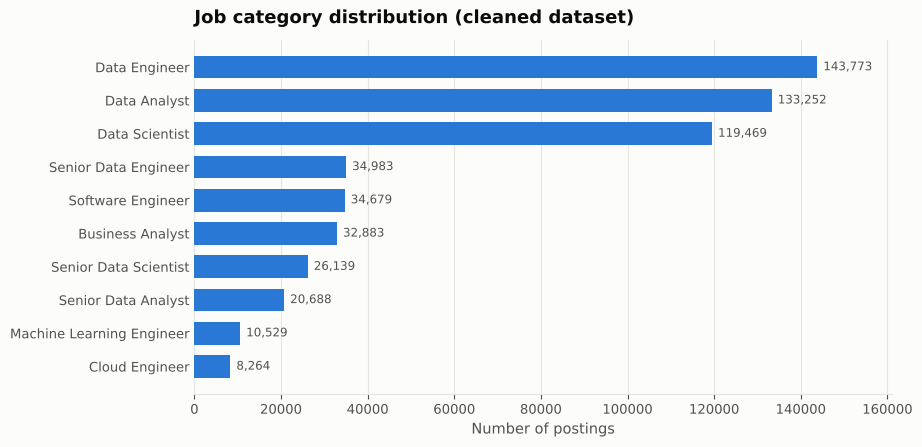

Imbalance ratio largest/smallest class: 17.4x


In [5]:
cat_counts = df[TARGET].value_counts()
fig, ax = plt.subplots(figsize=(9, 4.6))
viz.hbar(ax, cat_counts.index.tolist(), cat_counts.values.tolist(),
         "Job category distribution (cleaned dataset)", "Number of postings")
viz.save(fig, FIG, "01_job_category_distribution"); plt.show()
print(f"Imbalance ratio largest/smallest class: {cat_counts.max()/cat_counts.min():.1f}x")

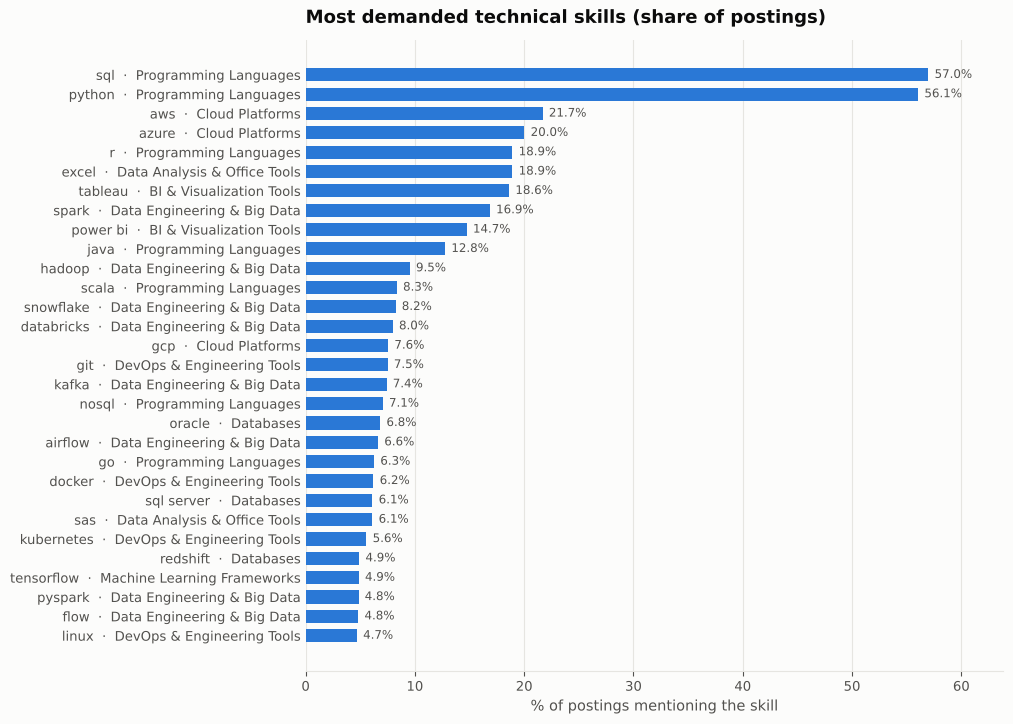

In [6]:
skill_counter = Counter(s for lst in df["skills"] for s in lst)
top30 = skill_counter.most_common(30)
fig, ax = plt.subplots(figsize=(9, 8.2))
viz.hbar(ax, [s for s, _ in top30], [c / len(df) * 100 for _, c in top30],
         "Most demanded technical skills (share of postings)", "% of postings mentioning the skill",
         fmt="{:.1f}%", sublabels=[extractor.skill2cat[s] for s, _ in top30])
viz.save(fig, FIG, "02_top_skills"); plt.show()

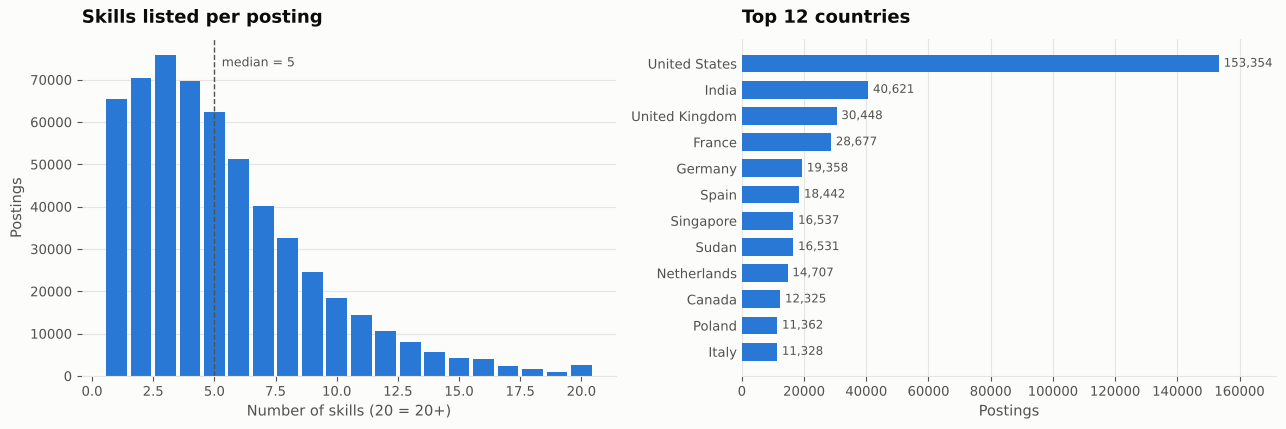

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ns = df["n_skills"].clip(upper=20)
axes[0].hist(ns, bins=np.arange(0.5, 21.5, 1), color=viz.PRIMARY, rwidth=0.85, zorder=2)
axes[0].set_title("Skills listed per posting", loc="left"); axes[0].set_xlabel("Number of skills (20 = 20+)")
axes[0].set_ylabel("Postings"); axes[0].grid(axis="x", visible=False)
axes[0].axvline(df["n_skills"].median(), color=viz.INK2, ls="--", lw=1)
axes[0].text(df["n_skills"].median() + 0.3, axes[0].get_ylim()[1] * 0.92,
             f"median = {df['n_skills'].median():.0f}", color=viz.INK2, fontsize=9)
cty = df["job_country"].value_counts().head(12)
viz.hbar(axes[1], cty.index.tolist(), cty.values.tolist(), "Top 12 countries", "Postings")
plt.tight_layout(); viz.save(fig, FIG, "03_skills_per_posting_countries"); plt.show()

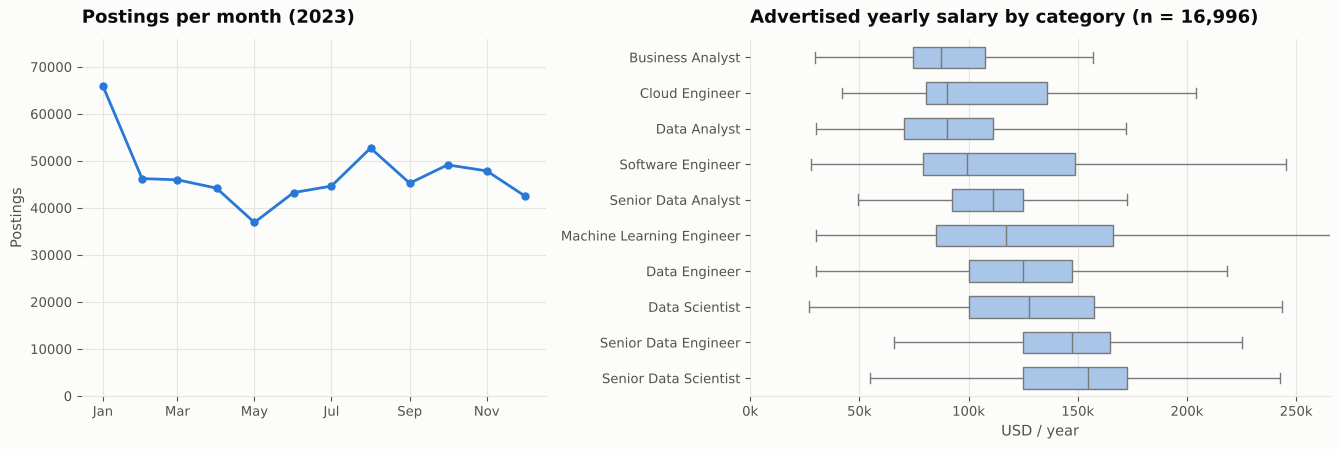

Remote (work from home) share: 9.8%


,postings
job_schedule_type,
Full-time,501023
Contractor,27962
Unknown,9171
Internship,6078
Part-time,5258
Full-time and Part-time,4781


In [8]:
monthly = df.set_index("job_posted_date").resample("MS").size()
monthly = monthly[(monthly.index >= "2023-01-01") & (monthly.index < "2024-01-01")]
sal = df.dropna(subset=["salary_year_avg"])
order = sal.groupby(TARGET)["salary_year_avg"].median().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
axes[0].plot(monthly.index, monthly.values, color=viz.PRIMARY, lw=2, marker="o", ms=5)
axes[0].set_title("Postings per month (2023)", loc="left"); axes[0].set_ylabel("Postings")
axes[0].set_ylim(0, monthly.max() * 1.15)
axes[0].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
sns.boxplot(data=sal, y=TARGET, x="salary_year_avg", order=order, ax=axes[1], color="#9ec5f4",
            fliersize=0, linewidth=1, width=0.6)
axes[1].set_xlim(0, sal["salary_year_avg"].quantile(0.99))
axes[1].set_title(f"Advertised yearly salary by category (n = {len(sal):,})", loc="left")
axes[1].set_xlabel("USD / year"); axes[1].set_ylabel("")
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
plt.tight_layout(); viz.save(fig, FIG, "04_monthly_and_salary"); plt.show()
print(f"Remote (work from home) share: {df['job_work_from_home'].mean():.1%}")
display(df["job_schedule_type"].value_counts().head(6).to_frame("postings"))

**EDA observations**

* The three junior or mid-level classes (Data Engineer, Data Analyst, Data Scientist) make up about 70 % of the data. ML Engineer and Cloud Engineer are 17x rarer than Data Engineer, so macro-averaged metrics are needed in evaluation.
* SQL and Python dominate. The cloud (AWS, Azure), BI (Tableau, Power BI) and big-data (Spark) stacks follow.
* Salaries are published in only a small, US-heavy subset. Senior and ML roles have the highest medians.

## 7. Skill extraction

**Approach (implemented in `jobnlp/skills.py`):**

1. **Gazetteer.** The canonical vocabulary is the ≈ 250 technologies found in the dataset's own `job_type_skills`. It is re-organised into 11 project categories: programming languages, BI tools, ML frameworks, databases, cloud, data engineering and so on. A small set of domain concepts that the dataset vocabulary lacks (machine learning, ETL, LLM, ...) is added.
2. **Alias normalisation.** `PowerBI`, `power-bi` → `power bi`; `sklearn` → `scikit-learn`; `k8s` → `kubernetes`; ...
3. **Phrase matching.** One compiled regex tries the longest alternatives first (`sql server` before `sql`, `t-sql` before `sql`). Custom token boundaries keep `c++`, `c#` and `node.js` intact.
4. **Ambiguity rules.** Single letters and common English words (`R`, `C`, `Go`, `Word`, `Swift`, `Spring`, ...) match only in their case-sensitive technical spelling. `R&D` and `C-level` are rejected explicitly.
5. **Semantic layer.** Every skill is embedded with DistilBERT (Section 11) to find semantically related skills.

*A spaCy NER model was not used:* no annotated skill corpus is available for training it, and the dataset vocabulary already gives a high-precision dictionary.

In [9]:
cat_sizes = pd.Series({c: len(v) for c, v in SKILL_CATEGORIES.items()}, name="skills in dictionary")
display(cat_sizes.to_frame())
print("Total canonical skills:", len(extractor.skill2cat), "| aliases:", len(extractor.aliases))

# Real dataset records: titles that mention technologies
mask = df["job_title"].str.contains(r"(?i)python|sql|aws|azure|spark|tableau|power ?bi|java|snowflake|databricks")
demo = df[mask].sample(8, random_state=SEED)
display(pd.DataFrame({
    "job_title (real record)": demo["job_title"].values,
    "extracted from title": [", ".join(extractor.extract_names(t)) for t in demo["job_title"]],
    "dataset skill tags": [", ".join(s[:8]) for s in demo["skills"]],
}))

,skills in dictionary
Programming Languages,49
BI & Visualization Tools,14
Data Analysis & Office Tools,22
Machine Learning Frameworks,15
Data Engineering & Big Data,10
Databases,20
Cloud Platforms,11
DevOps & Engineering Tools,31
Web & App Frameworks,37
Collaboration Tools,28


Total canonical skills: 258 | aliases: 66


,job_title (real record),extracted from title,dataset skill tags
0,Azure Data Factory Engineer,azure,"azure, sql"
1,Senior Data Engineer (Java),java,"aws, excel, java, mysql, postgresql, scala, sp..."
2,Azure Data Engineer,azure,"azure, databricks, python, sql"
3,Dubai Full Stack Software Engr Tableau/bi Anal...,tableau,tableau
4,Retail Banking Business Data Analyst with SQL,sql,sql
5,DATA ENGINEER SCALA/SPARK (H/F),"scala, spark","ansible, aws, azure, databricks, gitlab, jenki..."
6,Data Engineer AWS,aws,"aws, bash, confluence, gitlab, javascript, jen..."
7,"AWS Data Engineer (Senior)- AWS - EKS, AWS - C...",aws,"ansible, aws, azure, debian, docker, git, gitl..."


**Quantitative check against the dataset tags.** Full descriptions are not available, so the extractor is evaluated on the real **job titles**. A skill extracted from a title is counted correct when the posting's own `job_skills` tags (produced by the dataset author from the full description) contain it too. This measures **precision**, and only for skills of the tag vocabulary: the added concepts (machine learning, ETL, ...) are never tagged, so they cannot be checked. Recall cannot be measured on titles, because most skills appear only in the unseen description. The precision is also a *lower bound*: a technology named in a title but missing from the author's tags counts as an error even when the extraction is right.

In [10]:
# Only skills that exist in the dataset's tag vocabulary can be confirmed by the tags;
# the added "Data & AI Concepts" (machine learning, ETL...) are never tagged, so they are excluded.
tag_vocab = {s for lst in df["skills"] for s in lst}
title_ex = df["job_title"].map(extractor.extract_names)
n_concepts = int(sum(sum(s not in tag_vocab for s in e) for e in title_ex))
pairs = [([s for s in e if s in tag_vocab], set(t)) for e, t in zip(title_ex, df["skills"])]
pairs = [(e, t) for e, t in pairs if e]
n_pred = sum(len(e) for e, _ in pairs)
n_ok = sum(sum(s in t for s in e) for e, t in pairs)
skill_eval = {"titles_with_extracted_skill": len(pairs), "extracted_mentions": n_pred,
              "precision_vs_tags": n_ok / max(n_pred, 1),
              "concept_mentions_not_evaluable": n_concepts}
print(json.dumps(skill_eval, indent=2))
per_skill = Counter(s for e, _ in pairs for s in e)
per_ok = Counter(s for e, t in pairs for s in e if s in t)
prec = pd.DataFrame({"extracted": per_skill, "confirmed_by_tags": per_ok}).fillna(0)
prec["precision"] = prec["confirmed_by_tags"] / prec["extracted"]
display(prec.sort_values("extracted", ascending=False).head(12).style.format({"precision": "{:.1%}"}))

{
  "titles_with_extracted_skill": 47574,
  "extracted_mentions": 58234,
  "precision_vs_tags": 0.9222962530480475,
  "concept_mentions_not_evaluable": 30945
}


,extracted,confirmed_by_tags,precision
azure,9949,9759.000000,98.1%
python,8823,8385.000000,95.0%
aws,5950,5743.000000,96.5%
sql,5034,4662.000000,92.6%
gcp,3487,2789.000000,80.0%
power bi,2966,2603.000000,87.8%
java,2132,1982.000000,93.0%
snowflake,1906,1849.000000,97.0%
tableau,1477,1425.000000,96.5%
sap,1442,1401.000000,97.2%


In [11]:
examples = [
    "We are looking for a Data Engineer to build batch and streaming pipelines with Apache Spark, Kafka "
    "and Airflow on AWS (S3, Redshift). Strong SQL, Python and dbt. Docker and Kubernetes are a plus. "
    "You will report to our C-level and work closely with the R&D team.",
    "Junior BI analyst: build Power BI and Tableau dashboards, write T-SQL against SQL Server, "
    "automate reports in Excel/VBA. Knowledge of R or Python appreciated.",
]
for t in examples:
    print("INPUT :", t[:110], "...")
    for cat, sk in extractor.by_category(t).items():
        print(f"   {cat:<30} {', '.join(sk)}")
    print()

INPUT : We are looking for a Data Engineer to build batch and streaming pipelines with Apache Spark, Kafka and Airflow ...
   Data Engineering & Big Data    spark, kafka, airflow
   Cloud Platforms                aws
   Databases                      redshift
   Programming Languages          sql, python
   Data & AI Concepts             dbt
   DevOps & Engineering Tools     docker, kubernetes

INPUT : Junior BI analyst: build Power BI and Tableau dashboards, write T-SQL against SQL Server, automate reports in  ...
   BI & Visualization Tools       power bi, tableau
   Programming Languages          t-sql, vba, r, python
   Databases                      sql server
   Data Analysis & Office Tools   excel



The example sentences above are illustrative inputs written for this demo, not dataset records. Note that `C-level` and `R&D` are correctly ignored, while `R or Python` yields `r`.

**Skills by job category.** Each cell gives the share of the category's postings that list the skill.

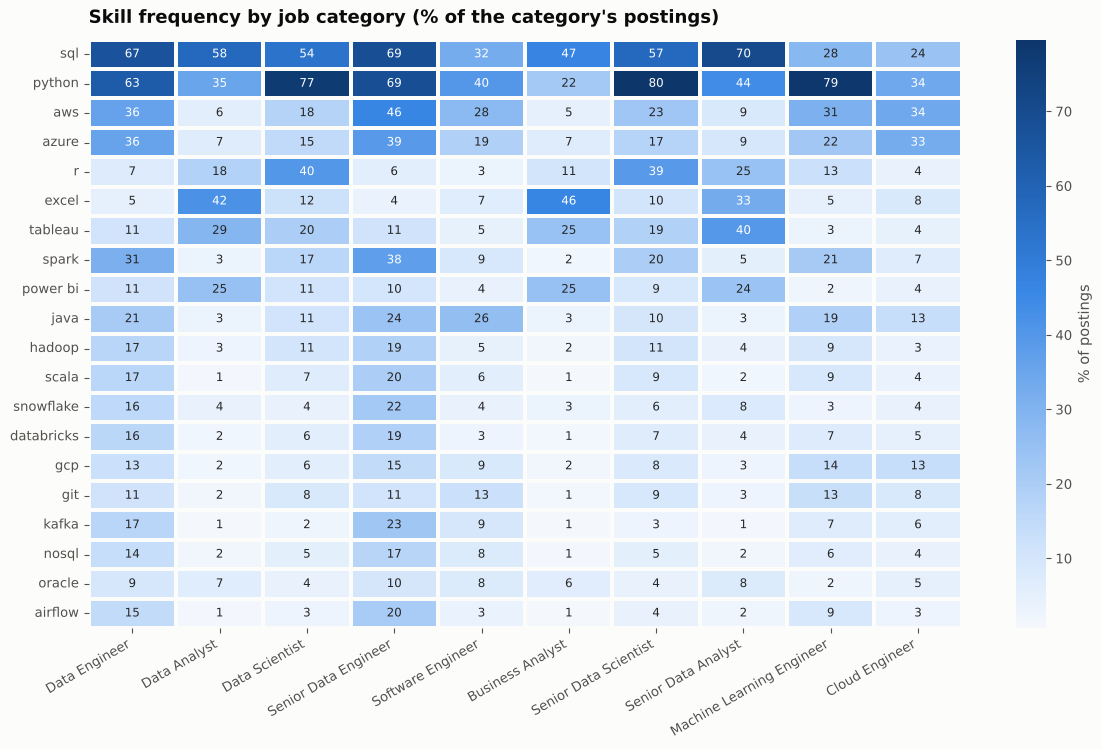

In [12]:
top_sk = [s for s, _ in skill_counter.most_common(20)]
jobs_order = cat_counts.index.tolist()
share = pd.DataFrame(0.0, index=top_sk, columns=jobs_order)
for j in jobs_order:
    sub = df.loc[df[TARGET] == j, "skills"]
    c = Counter(s for lst in sub for s in lst)
    share[j] = [c[s] / len(sub) for s in top_sk]
fig, ax = plt.subplots(figsize=(12, 7.6))
sns.heatmap(share * 100, annot=True, fmt=".0f", cmap=viz.SEQ_BLUE, cbar_kws={"label": "% of postings"},
            linewidths=1.5, linecolor=viz.SURFACE, ax=ax, annot_kws={"fontsize": 8.5})
ax.set_title("Skill frequency by job category (% of the category's postings)", loc="left")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right"); ax.set_ylabel(""); ax.grid(False)
plt.tight_layout(); viz.save(fig, FIG, "05_skills_by_category_heatmap"); plt.show()

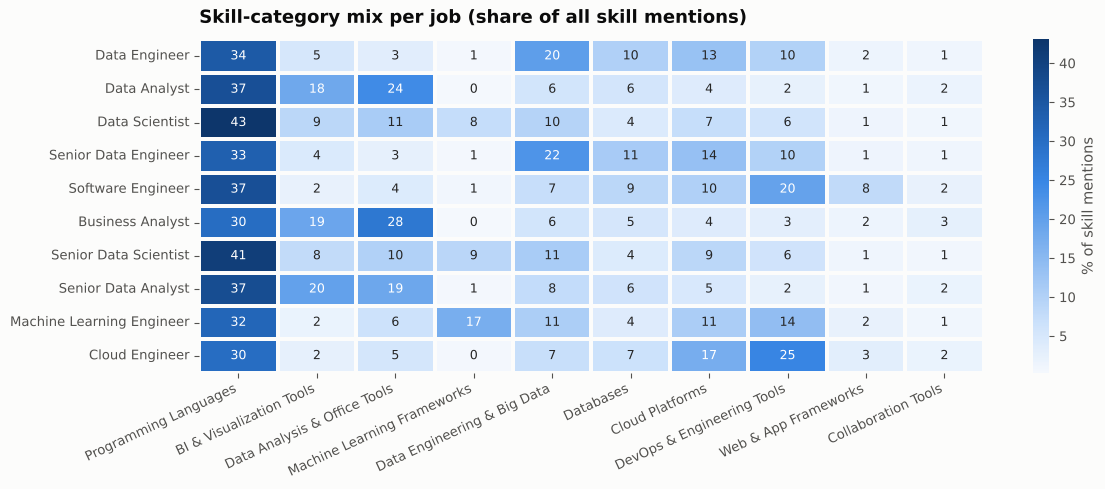

In [13]:
cat_share = pd.DataFrame(0.0, index=jobs_order, columns=list(SKILL_CATEGORIES))
for j in jobs_order:
    sub = df.loc[df[TARGET] == j, "skills"]
    c = Counter(extractor.skill2cat[s] for lst in sub for s in lst)
    tot = sum(c.values())
    cat_share.loc[j] = [c[k] / tot for k in cat_share.columns]
cat_share = cat_share.loc[:, cat_share.max() > 0.02]
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(cat_share * 100, annot=True, fmt=".0f", cmap=viz.SEQ_BLUE, linewidths=1.5,
            linecolor=viz.SURFACE, cbar_kws={"label": "% of skill mentions"}, ax=ax, annot_kws={"fontsize": 9})
ax.set_title("Skill-category mix per job (share of all skill mentions)", loc="left")
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right"); ax.grid(False)
plt.tight_layout(); viz.save(fig, FIG, "06_skill_category_mix"); plt.show()

**Limitations of the skill extractor.** It does not understand context: "Excel at teamwork" still yields `excel`. Technologies outside the dictionary are not detected. A sentence-initial "Go" or "Swift" can be a false positive. Each skill has one fixed category; for example SAS is listed as an analysis tool even when it is used as a language.

## 8. TF-IDF feature extraction

* **Document:** `text_tfidf`, i.e. the lower-cased job title plus the skill list, with `+ # . /` kept so that `c++`, `c#` and `node.js` survive.
* **Vectoriser:** word unigrams + bigrams, `min_df=3` (drops typos and hapaxes), `max_features=150 000`, `sublinear_tf=True` (log-scaled term frequency), L2 normalisation.
* **Split:** 80 / 20 **stratified** train/test (`random_state=42`). A 10 % validation split of the training set is used to choose `C`. The vectoriser sits inside the `Pipeline`, so its vocabulary and IDF are learned **on the training data only** (no leakage).
* **Second model (honest baseline):** **skills only** (one token per skill). It answers the question "how much of the profession can be inferred from the skills alone?"

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, f1_score)

train_df, test_df = train_test_split(df, test_size=0.2, stratify=df[TARGET], random_state=SEED)
print(f"train {len(train_df):,} | test {len(test_df):,}")
print("Test titles also present verbatim in train:",
      f"{test_df['job_title'].isin(set(train_df['job_title'])).mean():.1%}",
      "(different companies / ads with the same title - expected, not duplicates)")

def make_title_skill_pipeline(C):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=150_000, sublinear_tf=True)),
        ("clf", LogisticRegression(C=C, max_iter=300, solver="saga")),
    ])

train 451,727 | test 112,932
Test titles also present verbatim in train: 71.6% (different companies / ads with the same title - expected, not duplicates)


## 9. Logistic Regression training

Multinomial logistic regression (the `saga` solver handles large sparse matrices well), with a small grid over the inverse regularisation strength `C`, scored by macro-F1 on the validation split.

In [15]:
tr_in, val_in = train_test_split(train_df, test_size=0.1, stratify=train_df[TARGET], random_state=SEED)
grid = {}
for C in (0.5, 2.0, 8.0):
    t0 = time.time()
    p = make_title_skill_pipeline(C).fit(tr_in["text_tfidf"], tr_in[TARGET])
    grid[C] = f1_score(val_in[TARGET], p.predict(val_in["text_tfidf"]), average="macro")
    print(f"C={C:<4} validation macro-F1={grid[C]:.4f}  ({time.time()-t0:.0f}s)")
BEST_C = max(grid, key=grid.get)
print("Selected C =", BEST_C)

t0 = time.time()
clf_pipeline = make_title_skill_pipeline(BEST_C).fit(train_df["text_tfidf"], train_df[TARGET])
print(f"Final title+skills model trained on {len(train_df):,} ads in {time.time()-t0:.0f}s; "
      f"vocabulary = {len(clf_pipeline.named_steps['tfidf'].vocabulary_):,} n-grams")

skills_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer=skill_analyzer, min_df=2, sublinear_tf=True)),
    ("clf", LogisticRegression(C=1.0, max_iter=300, solver="saga")),
]).fit(train_df["skills_str"], train_df[TARGET])
baseline = DummyClassifier(strategy="most_frequent").fit(train_df["text_tfidf"], train_df[TARGET])

C=0.5  validation macro-F1=0.8869  (17s)
C=2.0  validation macro-F1=0.9067  (19s)
C=8.0  validation macro-F1=0.9148  (32s)
Selected C = 8.0
Final title+skills model trained on 451,727 ads in 34s; vocabulary = 52,014 n-grams


## 10. Classification evaluation

In [16]:
def evaluate(name, y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {"model": name, "accuracy": accuracy_score(y_true, y_pred), "precision_macro": p,
            "recall_macro": r, "f1_macro": f, "precision_weighted": pw, "recall_weighted": rw,
            "f1_weighted": fw}

y_test = test_df[TARGET]
pred_main = clf_pipeline.predict(test_df["text_tfidf"])
pred_skills = skills_pipeline.predict(test_df["skills_str"])
pred_base = baseline.predict(test_df["text_tfidf"])
results = pd.DataFrame([
    evaluate("Majority-class baseline", y_test, pred_base),
    evaluate("TF-IDF + LogReg (skills only)", y_test, pred_skills),
    evaluate("TF-IDF + LogReg (title + skills) - MAIN", y_test, pred_main),
]).set_index("model")
display(results.style.format("{:.4f}").background_gradient(cmap=viz.SEQ_BLUE, axis=0))

,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
model,,,,,,,
Majority-class baseline,0.2546,0.0255,0.1000,0.0406,0.0648,0.2546,0.1033
TF-IDF + LogReg (skills only),0.5150,0.4479,0.2551,0.2364,0.4899,0.5150,0.4452
TF-IDF + LogReg (title + skills) - MAIN,0.9487,0.9244,0.9127,0.9183,0.9485,0.9487,0.9486


In [17]:
report = classification_report(y_test, pred_main, digits=4, output_dict=True)
rep_df = pd.DataFrame(report).T
display(rep_df.style.format({"precision": "{:.4f}", "recall": "{:.4f}", "f1-score": "{:.4f}",
                             "support": "{:,.0f}"}))

,precision,recall,f1-score,support
Business Analyst,0.9081,0.9183,0.9132,"6,576"
Cloud Engineer,0.8340,0.7689,0.8001,"1,653"
Data Analyst,0.9590,0.9610,0.9600,"26,650"
Data Engineer,0.9720,0.9758,0.9739,"28,755"
Data Scientist,0.9534,0.9564,0.9549,"23,894"
Machine Learning Engineer,0.9290,0.8879,0.9080,"2,106"
Senior Data Analyst,0.9028,0.8707,0.8864,"4,137"
Senior Data Engineer,0.9510,0.9461,0.9486,"6,997"
Senior Data Scientist,0.9275,0.9130,0.9202,"5,228"
Software Engineer,0.9069,0.9288,0.9177,"6,936"


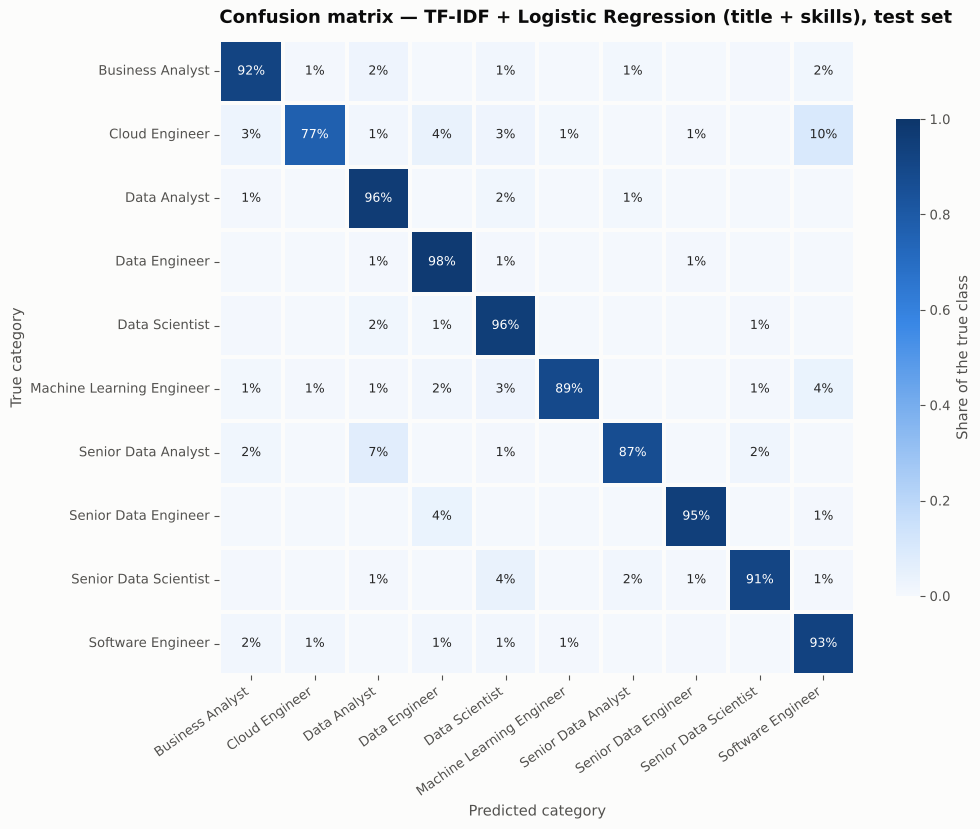

In [18]:
labels = sorted(df[TARGET].unique())
cm = confusion_matrix(y_test, pred_main, labels=labels)
cm_norm = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(10.5, 8.4))
annot = np.array([[f"{v:.0%}" if v >= 0.005 else "" for v in row] for row in cm_norm])
sns.heatmap(cm_norm, annot=annot, fmt="", cmap=viz.SEQ_BLUE, vmin=0, vmax=1, xticklabels=labels,
            yticklabels=labels, linewidths=1.5, linecolor=viz.SURFACE, ax=ax, square=True,
            cbar_kws={"label": "Share of the true class", "shrink": 0.75}, annot_kws={"fontsize": 9})
ax.set_xlabel("Predicted category"); ax.set_ylabel("True category"); ax.grid(False)
ax.set_title("Confusion matrix — TF-IDF + Logistic Regression (title + skills), test set", loc="left")
ax.set_xticklabels(labels, rotation=35, ha="right")
plt.tight_layout(); viz.save(fig, FIG, "07_confusion_matrix"); plt.show()

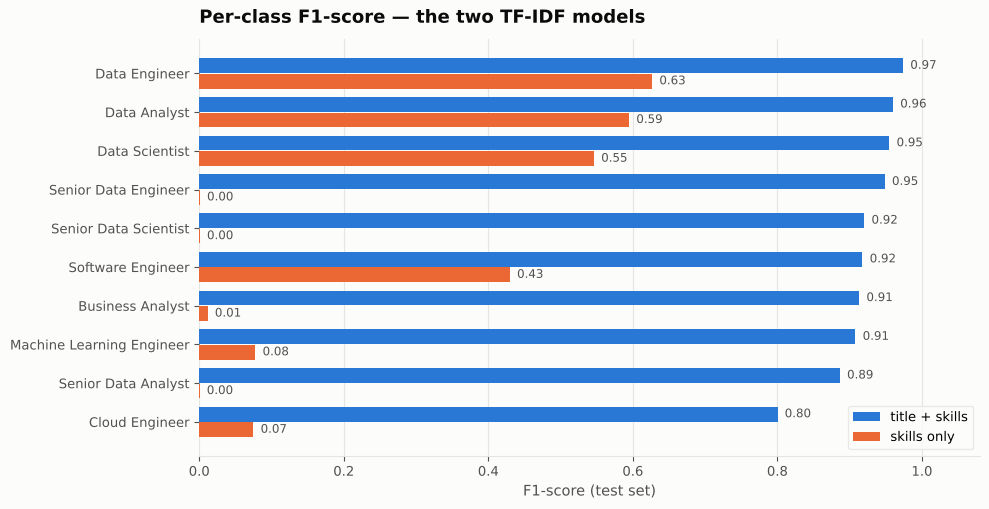

In [19]:
f1_main = pd.Series({l: report[l]["f1-score"] for l in labels})
rep_sk = classification_report(y_test, pred_skills, output_dict=True, zero_division=0)
f1_sk = pd.Series({l: rep_sk[l]["f1-score"] for l in labels})
order_f1 = f1_main.sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.2))
y = np.arange(len(order_f1))
ax.barh(y + 0.2, f1_main[order_f1], height=0.38, color=viz.CATEGORICAL[0], label="title + skills", zorder=2)
ax.barh(y - 0.2, f1_sk[order_f1], height=0.38, color=viz.CATEGORICAL[1], label="skills only", zorder=2)
for yi, a, b in zip(y, f1_main[order_f1], f1_sk[order_f1]):
    ax.text(a + 0.01, yi + 0.2, f"{a:.2f}", va="center", fontsize=8.5, color=viz.INK2)
    ax.text(b + 0.01, yi - 0.2, f"{b:.2f}", va="center", fontsize=8.5, color=viz.INK2)
ax.set_yticks(y, order_f1); ax.set_xlim(0, 1.08); ax.set_xlabel("F1-score (test set)")
ax.set_title("Per-class F1-score — the two TF-IDF models", loc="left"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=True, facecolor=viz.SURFACE, edgecolor=viz.GRID)
plt.tight_layout(); viz.save(fig, FIG, "08_per_class_f1"); plt.show()

In [20]:
# Most discriminative n-grams per class (largest positive coefficients)
vec, lr = clf_pipeline.named_steps["tfidf"], clf_pipeline.named_steps["clf"]
fn = np.array(vec.get_feature_names_out())
top_feats = {c: ", ".join(fn[np.argsort(-lr.coef_[i])[:8]]) for i, c in enumerate(lr.classes_)}
display(pd.DataFrame.from_dict(top_feats, orient="index", columns=["top weighted n-grams"]))

# Error analysis
errs = test_df.assign(pred=pred_main)[pred_main != y_test]
conf_pairs = errs.groupby([TARGET, "pred"]).size().sort_values(ascending=False).head(8)
display(conf_pairs.to_frame("errors"))
display(errs[["job_title", "skills_str", TARGET, "pred"]].sample(8, random_state=SEED))

,top weighted n-grams
Business Analyst,"business, bi, analyst, business analyst, skill..."
Cloud Engineer,"cloud, skills, cloud engineer, web, infrastruc..."
Data Analyst,"data analyst, data, analyst, analytics, intell..."
Data Engineer,"data, data engineer, engineer, data engineerin..."
Data Scientist,"data scientist, data, skills, scientist, data ..."
Machine Learning Engineer,"ml, learning, engineer, learning engineer, ai,..."
Senior Data Analyst,"senior, data analyst, analyst, sr, senior data..."
Senior Data Engineer,"senior, senior data, data engineer, engineer, ..."
Senior Data Scientist,"senior, data scientist, sr, senior data, scien..."
Software Engineer,"software, software engineer, skills, developer..."


,,errors
job_title_short,pred,
Data Analyst,Data Scientist,436
Data Scientist,Data Analyst,379
Senior Data Analyst,Data Analyst,294
Senior Data Engineer,Data Engineer,257
Data Scientist,Data Engineer,227
Data Analyst,Senior Data Analyst,217
Data Engineer,Senior Data Engineer,217
Senior Data Scientist,Data Scientist,214


,job_title,skills_str,job_title_short,pred
458089,Sr Data Engineer - Big Data Developer,airflow|azure|databricks|git|python|snowflake|...,Senior Data Engineer,Data Engineer
459964,Senior Actuarial Specialist - Reporting and An...,power bi|r|sql|tableau|vba,Senior Data Analyst,Business Analyst
297305,CIENTISTA DE DADOS SENIOR (100% REMOTO),git|python|sql,Data Scientist,Business Analyst
471978,"Market Data Business Analyst, Senior Associate",confluence|jira|sql,Senior Data Analyst,Business Analyst
14516,Data Scientist / AI Data Engineer,airflow|aws|python,Data Engineer,Data Scientist
421537,Qe Analyst,oracle|sql,Data Scientist,Business Analyst
142872,BI Developer/Analytics Engineer,airflow|aws|github|kafka|looker|power bi|pytho...,Business Analyst,Data Engineer
331939,IT Data Architect,cognos|crystal|db2|excel|microstrategy|mysql|n...,Data Engineer,Data Analyst


**Analysis of the classifier.**

* The main model reaches the accuracy and macro-F1 shown above, far above the majority baseline. Most of the signal comes from the **title**. This is expected: according to the dataset card, `job_title_short` was itself derived from `job_title`. These scores therefore measure how well the model reproduces that standardisation, not how well it reads a full description.
* The **skills-only** model is the honest measure of how much the *skill profile* reveals. It separates the families (analyst / engineer / scientist / cloud) but cannot tell **seniority** apart: *Senior Data Engineer* and *Data Engineer* have almost identical skills.
* **Remaining weaknesses** of the main model (see the error tables):
  1. **Data Analyst ↔ Data Scientist** is the largest confusion. The professions overlap (Python, SQL, R), and titles such as "Analytics", "Data Analyst/Scientist" or non-English titles ("Cientista de dados") are ambiguous.
  2. **Seniority** (Senior X ↔ X) when the title says "Lead", "Staff", "Principal", "Sr" or "II/III" in an unusual way, or does not state the level at all.
  3. **Hybrid titles** ("Data Engineer/Scientist/Analyst", "BI Developer/Analytics Engineer") where the gold label is somewhat arbitrary.
  4. **Cloud Engineer** has the lowest F1: it is a small class whose titles mix with DevOps and Software Engineer.
  5. Some gold labels look noisy, because the dataset's own BERT labeller makes mistakes too (e.g. "Qe Analyst" labelled Data Scientist).
* Class imbalance has a limited effect: rare classes with distinctive titles (ML Engineer) keep a good F1, while the macro-F1 sits about 3 points below the accuracy.

In [21]:
# --- Save the classification artifacts ---
joblib.dump(clf_pipeline, MODELS / "classification_pipeline.joblib", compress=3)
joblib.dump(clf_pipeline.named_steps["tfidf"], MODELS / "tfidf_vectorizer.joblib", compress=3)
joblib.dump(clf_pipeline.named_steps["clf"], MODELS / "logistic_regression.joblib", compress=3)
joblib.dump(skills_pipeline, MODELS / "skills_only_pipeline.joblib", compress=3)
classification_metrics = {
    "split": {"train": len(train_df), "test": len(test_df), "stratified": True, "random_state": SEED},
    "grid_search_val_macro_f1": {str(k): v for k, v in grid.items()}, "best_C": BEST_C,
    "models": results.reset_index().to_dict(orient="records"),
    "classification_report": report, "labels": labels, "confusion_matrix": cm.tolist(),
    "skills_only_report": rep_sk,
    "top_features": top_feats,
    "top_confusions": [{"true": a, "pred": b, "count": int(n)} for (a, b), n in conf_pairs.items()],
}
(METRICS / "classification_metrics.json").write_text(json.dumps(classification_metrics, indent=2, default=float))
for f in ["classification_pipeline", "tfidf_vectorizer", "logistic_regression", "skills_only_pipeline"]:
    print(f"saved models/{f}.joblib  ({(MODELS / (f + '.joblib')).stat().st_size/1e6:.1f} MB)")

saved models/classification_pipeline.joblib  (4.5 MB)
saved models/tfidf_vectorizer.joblib  (0.6 MB)
saved models/logistic_regression.joblib  (3.9 MB)
saved models/skills_only_pipeline.joblib  (0.0 MB)


## 11. DistilBERT loading and embedding generation

**Checkpoint:** `distilbert-base-uncased` (66 M parameters; 6 layers, 12 heads, hidden size 768), the official Hugging Face weights in `model.safetensors`.

**Implementation.** `jobnlp/distilbert.py` re-implements the DistilBERT forward pass in **NumPy**, and `jobnlp/tokenizer.py` re-implements the WordPiece tokenizer. They read the official weight file directly. As a result the project runs without PyTorch or `transformers`, which were not available in the environment used to build it. This is *inference only*: no weight is changed.

**Correctness check.** The model's masked-language-model head must reproduce the predictions published on the model card (`"Hello I'm a [MASK] model."` → *role, fashion, business, model, modeling*). If `transformers` + `torch` are installed, the next cell also compares the hidden states numerically with the official implementation.

**Embedding strategy**
* Input text = `"<job title>. Skills: <skill list>."`. Inputs are tokenised up to **128 tokens** (`[CLS] … [SEP]`), and longer inputs are head-truncated; the cell below counts how many were cut.
* **Mean pooling** of the last hidden layer over the *valid* tokens only (the attention mask excludes padding), then L2 normalisation.
* **Batching:** texts are sorted by length and embedded in batches of 64 with *dynamic padding*, which keeps memory bounded and reduces wasted compute on padding.
* **Caching:** embeddings are written to `models/job_embeddings.npy` together with a fingerprint of the job ids. Re-running the notebook reloads them instead of recomputing; set `RECOMPUTE_EMBEDDINGS = True` to force a recomputation.

**Limitation — DistilBERT is not a sentence-similarity model.** It was pre-trained for masked-language modelling only, not with a contrastive or sentence-pair objective like Sentence-BERT. Its mean-pooled vectors are an *unsupervised* semantic representation: good at grouping texts on related topics, but the raw cosine scores are compressed into a narrow, high range (anisotropy) and are not calibrated. This is handled by **centering** the vectors (subtracting the corpus mean) before cosine similarity and clustering, and similarities are only interpreted *relatively*, as a ranking.

In [22]:
encoder = DistilBertEncoder(BERT_DIR, max_len=128)
print(f"DistilBERT loaded from {BERT_DIR.relative_to(PROJECT_ROOT) if BERT_DIR != PROJECT_ROOT else '.'}"
      f" — {encoder.n_params/1e6:.1f}M parameters, {encoder.config['n_layers']} layers, dim {encoder.dim}")
for s in ["Hello I'm a [MASK] model.", "The capital of France is [MASK].",
          "I write my data pipelines in [MASK] and SQL."]:
    print(f"  fill-mask  {s:<48} -> {encoder.fill_mask(s)}")
print("WordPiece example:", encoder.tokenizer.tokenize("Senior Data Engineer – PySpark, Databricks & Kubernetes"))

try:   # optional numerical cross-check with the official implementation
    import torch
    from transformers import AutoTokenizer, AutoModel
    hf_tok = AutoTokenizer.from_pretrained(str(BERT_DIR)); hf_model = AutoModel.from_pretrained(str(BERT_DIR)).eval()
    txt = "Data Engineer. Skills: python, sql, spark."
    with torch.no_grad():
        hf_h = hf_model(**hf_tok(txt, return_tensors="pt")).last_hidden_state[0].numpy()
    ids, m, _ = encoder.tokenizer.batch_encode([txt])
    print("max |numpy - transformers| hidden state difference:",
          float(np.abs(encoder.hidden_states(ids, m)[0] - hf_h).max()))
except ImportError:
    print("transformers/torch not installed - numerical cross-check skipped (the fill-mask check above validates the weights)")

DistilBERT loaded from models/distilbert-base-uncased — 67.0M parameters, 6 layers, dim 768
  fill-mask  Hello I'm a [MASK] model.                        -> ['role', 'fashion', 'business', 'model', 'modeling']
  fill-mask  The capital of France is [MASK].                 -> ['marseille', 'nantes', 'toulouse', 'paris', 'lyon']
  fill-mask  I write my data pipelines in [MASK] and SQL.     -> ['xml', 'java', 'php', 'html', 'ruby']
WordPiece example: ['senior', 'data', 'engineer', '–', 'p', '##ys', '##park', ',', 'data', '##brick', '##s', '&', 'ku', '##ber', '##net', '##es']
transformers/torch not installed - numerical cross-check skipped (the fill-mask check above validates the weights)


In [23]:
corpus = sample_for_embedding(df, per_class=1500, seed=SEED)
lens = [len(encoder.tokenizer.tokenize_ids(t)) + 2 for t in corpus["text_embed"]]
print(f"Embedding corpus: {len(corpus):,} postings (class-balanced, 1,500 per category)")
print(f"Token length: median {np.median(lens):.0f}, 95th pct {np.percentile(lens, 95):.0f}, "
      f"max {max(lens)}; truncated at 128 tokens: {sum(l > 128 for l in lens)} texts")

emb_raw = compute_or_load_embeddings(lambda: encoder, corpus["text_embed"].tolist(), corpus["job_id"].values,
                                     MODELS / "job_embeddings.npy", batch_size=64, force=RECOMPUTE_EMBEDDINGS)
emb, emb_mean = center_normalize(emb_raw)
np.save(MODELS / "embedding_mean.npy", emb_mean)
rng = np.random.default_rng(SEED)
i, j = rng.integers(0, len(emb), 3000), rng.integers(0, len(emb), 3000)
print(f"Mean cosine between random pairs: raw {np.mean(np.sum(emb_raw[i]*emb_raw[j],1)):.3f} -> "
      f"centered {np.mean(np.sum(emb[i]*emb[j],1)):.3f} (anisotropy removed)")

Embedding corpus: 15,000 postings (class-balanced, 1,500 per category)
Token length: median 22, 95th pct 49, max 133; truncated at 128 tokens: 1 texts
Loaded cached embeddings job_embeddings.npy [15000, 768] (computed in 1238s)
Mean cosine between random pairs: raw 0.873 -> centered 0.007 (anisotropy removed)


In [24]:
# Skill embeddings - two strategies
skill_names = sorted(extractor.skill2cat)
# (a) name only: each skill name embedded alone, out of context
name_emb, _ = center_normalize(encoder.encode(skill_names, batch_size=128))
# (b) contextual: a skill = mean of the DistilBERT vectors of the job ads that require it
#     (needs >= 15 ads in the corpus; rarer skills fall back to (a))
MIN_ADS = 15
skill_rows = {s: [] for s in skill_names}
for r, lst in enumerate(corpus["skills"]):
    for s in lst:
        if s in skill_rows: skill_rows[s].append(r)
ctx_emb = name_emb.copy()
n_ctx = 0
for i, s in enumerate(skill_names):
    if len(skill_rows[s]) >= MIN_ADS:
        v = emb[skill_rows[s]].mean(0); ctx_emb[i] = v / np.linalg.norm(v); n_ctx += 1
skill_emb = ctx_emb
np.save(MODELS / "skill_embeddings.npy", skill_emb.astype(np.float32))
(MODELS / "skill_embedding_names.json").write_text(json.dumps(skill_names))
print(f"Contextual embeddings for {n_ctx} skills (>= {MIN_ADS} ads), name-only fallback for {len(skill_names)-n_ctx}")
rows = []
for s in ["pytorch", "tableau", "kafka", "aws", "postgresql", "excel", "kubernetes"]:
    i0 = skill_names.index(s)
    ia, sa = top_k_cosine(name_emb[i0], name_emb, k=5, exclude=i0)
    ib, sb = top_k_cosine(ctx_emb[i0], ctx_emb, k=5, exclude=i0)
    rows.append({"skill": s,
                 "(a) name-only neighbours": ", ".join(skill_names[k] for k in ia),
                 "(b) contextual neighbours": ", ".join(f"{skill_names[k]} ({v:.2f})" for k, v in zip(ib, sb))})
display(pd.DataFrame(rows))

Contextual embeddings for 157 skills (>= 15 ads), name-only fallback for 101


,skill,(a) name-only neighbours,(b) contextual neighbours
0,pytorch,"pyspark, xamarin, symfony, blazor, twilio","tensorflow (0.99), keras (0.98), scikit-learn ..."
1,tableau,"statistics, plotly, assembly, time series, kafka","looker (0.83), qlik (0.82), alteryx (0.75), sq..."
2,kafka,"django, ubuntu, snowflake, ruby on rails, pandas","cassandra (0.95), spark (0.94), hadoop (0.94),..."
3,aws,"sass, spss, apl, ssis, ssrs","gcp (0.96), spark (0.93), dynamodb (0.93), git..."
4,postgresql,"mysql, nosql, graphql, nuxt.js, asp.net core","mysql (0.97), nosql (0.94), redis (0.92), mong..."
5,excel,"sql, zoom, scala, ruby, outlook","powerpoint (0.87), word (0.82), outlook (0.76)..."
6,kubernetes,"blazor, xamarin, jupyter, microstrategy, pytorch","docker (0.98), terraform (0.95), jenkins (0.95..."


**Name-only** skill embeddings are weak: DistilBERT sees a bare word such as "pytorch" out of context and splits it into sub-words, so its neighbours are often lexical lookalikes. **Contextual** embeddings, where each skill is the centroid of the ads that require it, place a skill among the tools used in the same jobs, for example deep-learning frameworks together and BI tools together. The contextual version is saved and used by the app for "semantically related skills". Skill **recommendation** additionally uses co-occurrence in the knowledge graph (Section 16).

## 12. Semantic similarity analysis

The similarity between two ads is the cosine of their centered DistilBERT vectors. To find the ads most similar to any query (a job description or a skill profile), the query is embedded with the same pipeline and ranked with a dot product against the stored matrix.

**Keyword vs semantic comparison.** The same ranking is computed with a TF-IDF vectoriser fitted on the same corpus (pure keyword overlap).

In [25]:
kw_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
kw_matrix = kw_vec.fit_transform(corpus["text_tfidf"])

def semantic_search(query, k=5):
    q = encoder.encode([query], normalize=True)[0] - emb_mean
    q /= np.linalg.norm(q)
    idx, sims = top_k_cosine(q, emb, k=k)
    return corpus.iloc[idx].assign(similarity=sims)

def keyword_search(query, k=5):
    q = kw_vec.transform([clean_for_tfidf(query)])
    sims = (kw_matrix @ q.T).toarray().ravel()
    idx = np.argsort(-sims)[:k]
    return corpus.iloc[idx].assign(similarity=sims[idx])

queries = ["building deep neural networks for image recognition and object detection",
           "creating interactive dashboards and KPI reports for business stakeholders",
           "real-time event streaming infrastructure"]
for q in queries:
    display(Markdown(f"**Query:** *{q}*"))
    sem, kw = semantic_search(q), keyword_search(q)
    display(pd.DataFrame({
        "semantic (DistilBERT) — title | skills": (sem["job_title"] + " | " + sem["skills_str"].str.replace("|", ", ")).str[:85].values,
        "cos": sem["similarity"].round(3).values,
        "keyword (TF-IDF) — title | skills": (kw["job_title"] + " | " + kw["skills_str"].str.replace("|", ", ")).str[:85].values,
        "tfidf": kw["similarity"].round(3).values,
    }))

**Query:** *building deep neural networks for image recognition and object detection*

,semantic (DistilBERT) — title | skills,cos,keyword (TF-IDF) — title | skills,tfidf
0,"Machine Learning Research Scientist | pytorch,...",0.513,Senior Security Detection and Monitoring Engin...,0.276
1,"Computer Vision Engineer, Data Monetization Te...",0.462,Senior Data Scientist(EKYC/OCR/Facial Recognit...,0.273
2,"Machine Learning Engineer | pytorch, tensorflow",0.460,"Senior Data Engineer (Airflow, image recogniti...",0.268
3,"Machine Learning Engineer | pytorch, tensorflow",0.460,"Networks Engineer | linux, shell",0.268
4,Developer Machine Learning | flow,0.452,"image algorithm engineer | c++, windows",0.227


**Query:** *creating interactive dashboards and KPI reports for business stakeholders*

,semantic (DistilBERT) — title | skills,cos,keyword (TF-IDF) — title | skills,tfidf
0,Business System Analyst - Data Dashboards | jira,0.640,Company recruit for Business Analyst - Data Sc...,0.397
1,Enterprise PMO Data Analyst | sharepoint,0.595,Looking for immediate joiners for Business Dat...,0.337
2,Business Reporting Analyst | sharepoint,0.588,Business System Analyst - Data Dashboards | jira,0.295
3,Remote Business Data Analyst Analytics | windows,0.584,Post vacant for- Business Analyst-Reputed Anal...,0.292
4,"Senior Analyst, Deliver Data Strategy | azure",0.569,Business Analyst (Data Reporting/Dashboards) -...,0.273


**Query:** *real-time event streaming infrastructure*

,semantic (DistilBERT) — title | skills,cos,keyword (TF-IDF) — title | skills,tfidf
0,"Content Infrastructure Engineer, Live Streamin...",0.496,Senior Software Engineer - Streaming / Real ti...,0.621
1,Data Analytics Manager | azure,0.463,Real Time Analyst | excel,0.603
2,"IT Infrastructure Engineer | azure, sharepoint",0.461,Real Time Analyst | excel,0.603
3,Cloud Platform Engineer | azure,0.447,Senior Software Engineer - Real-time Data Infr...,0.453
4,Live Feed Analyst - Service Provider | react,0.447,"Content Infrastructure Engineer, Live Streamin...",0.373


**Interpretation (keyword vs semantic).**
* *Deep neural networks for image recognition.* TF-IDF matches the **words** "detection" and "networks" literally, so it returns a *Security Detection* engineer and a *Networks Engineer*. DistilBERT matches the **meaning** and returns ML research / computer-vision / ML engineer ads with *pytorch, tensorflow*, although none of them contains the query words.
* *Dashboards and KPI reports.* Both methods find reporting and business analysts. DistilBERT ranks reporting-oriented analyst ads higher even when the word "dashboard" is absent.
* *Real-time event streaming.* Here TF-IDF is better: titles literally contain "Real-time" and "Streaming", and the exact words are the best evidence. DistilBERT drifts toward generic infrastructure and "live" roles.

The comparison shows the trade-off: semantic similarity generalises to paraphrases but is coarser, while keyword similarity is precise when the vocabulary is shared but brittle otherwise.

**Quantitative comparison.** For 1,000 random ads, the 10 nearest neighbours are retrieved, and the score is the share of neighbours with the same `job_title_short` (label agreement@10; the labels are never used to build the vectors).

In [26]:
probe = rng.choice(len(corpus), 1000, replace=False)
y_corpus = corpus[TARGET].values
kw_norm = kw_matrix  # rows are L2-normalised by TfidfVectorizer
agree_sem, agree_kw = [], []
for p_i in probe:
    idx, _ = top_k_cosine(emb[p_i], emb, k=10, exclude=p_i)
    agree_sem.append(np.mean(y_corpus[idx] == y_corpus[p_i]))
    s = (kw_norm @ kw_norm[p_i].T).toarray().ravel(); s[p_i] = -1
    agree_kw.append(np.mean(y_corpus[np.argsort(-s)[:10]] == y_corpus[p_i]))
sim_eval = {"label_agreement@10_semantic": float(np.mean(agree_sem)),
            "label_agreement@10_tfidf": float(np.mean(agree_kw)),
            "random_baseline": float(np.mean([(y_corpus == y).mean() for y in y_corpus[probe]]))}
print(json.dumps(sim_eval, indent=2))

# example: nearest ads to one real ad
ref = corpus[corpus["job_title"].str.contains("Machine Learning", case=False)].index[0]
idx, sims = top_k_cosine(emb[ref], emb, k=6, exclude=ref)
print("\nReference ad:", corpus.loc[ref, "job_title"], "|", corpus.loc[ref, "skills_str"].replace("|", ", "))
display(corpus.iloc[idx][["job_title", "job_title_short", "company_name", "skills_str"]].assign(cosine=sims.round(3)))

{
  "label_agreement@10_semantic": 0.47959999999999997,
  "label_agreement@10_tfidf": 0.4726,
  "random_baseline": 0.10000000000000002
}

Reference ad: Lead Data Scientist/ Lead Machine Learning Engineer (Bangkok... | pyspark, python, scala, sql


,job_title,job_title_short,company_name,skills_str,cosine
8282,Lead Data Scientist/Lead Machine Learning Engi...,Machine Learning Engineer,Agoda,pyspark|python|scala|sql,0.981
3575,Data Scientist/ Machine Learning Engineer (Ban...,Machine Learning Engineer,Agoda,pyspark|python|scala|sql,0.948
11489,Lead Data Scientist/Machine Learning Engineer ...,Machine Learning Engineer,Agoda,pyspark|python|scala|sql,0.899
2382,Data Scientist/Machine Learning Engineer (Sing...,Machine Learning Engineer,Agoda,pyspark|python|scala|sql,0.886
8270,Data Scientist/Machine Learning Engineer (Sing...,Machine Learning Engineer,Agoda,pyspark|python|scala|sql,0.886
10509,Senior Data Analyst - Strong Python Skill (Ban...,Senior Data Analyst,Agoda,python|sql,0.807


Both representations retrieve neighbours of the same category about 4.8× more often than chance, and they are almost tied. TF-IDF has an advantage on this specific metric because the labels were derived from title words. DistilBERT reaches the same level without exact word overlap and also handles paraphrased queries (previous cell), so the two are complementary. The app shows the semantic score next to the skills shared with the query.

## 13. K-Means clustering

* **Representation:** the centered, L2-normalised DistilBERT embeddings (768-d). On unit vectors, Euclidean K-Means is equivalent to clustering by cosine similarity.
* **Algorithm:** `KMeans(n_init=10, random_state=42)` (k-means++ initialisation).

## 14. Optimal number of clusters

K is evaluated from 2 to 15 with two complementary criteria:
* **Elbow method:** within-cluster inertia. The elbow is located automatically as the K farthest from the straight line joining the two ends of the curve (the *Kneedle* idea).
* **Silhouette score** (cosine metric, 6,000-point sample): how much closer points are to their own cluster than to the next one.

**Selection rule (fixed before looking at the results):** the goal is to discover *professional families*, so K = 2 or 3 is too coarse. K is chosen as the **best silhouette within K ∈ [4, 12]**, and the elbow is used as a cross-check.

In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA

K_RANGE = list(range(2, 16))
inertias, silhouettes = [], []
sil_idx = rng.choice(len(emb), 6000, replace=False)
t0 = time.time()
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(emb)
    inertias.append(float(km.inertia_))
    silhouettes.append(float(silhouette_score(emb[sil_idx], km.labels_[sil_idx], metric="cosine")))
    print(f"K={k:>2}  inertia={km.inertia_:9.1f}  silhouette={silhouettes[-1]:.4f}")
print(f"({time.time()-t0:.0f}s)")

x = np.array(K_RANGE, float); yv = np.array(inertias)
xn, yn = (x - x.min()) / (x.max() - x.min()), (yv - yv.min()) / (yv.max() - yv.min())
dist = np.abs(yn - (1 - xn)) / np.sqrt(2)          # distance to the chord
K_ELBOW = int(x[np.argmax(dist)])
cand = [k for k in K_RANGE if 4 <= k <= 12]
K_BEST = max(cand, key=lambda k: silhouettes[K_RANGE.index(k)])
print(f"Elbow (Kneedle) K = {K_ELBOW} | best silhouette in [4,12]: K = {K_BEST}")

K= 2  inertia=  11412.8  silhouette=0.3633
K= 3  inertia=  10665.9  silhouette=0.2683
K= 4  inertia=  10187.1  silhouette=0.2436
K= 5  inertia=   9875.8  silhouette=0.2389
K= 6  inertia=   9616.9  silhouette=0.1767
K= 7  inertia=   9413.5  silhouette=0.1491
K= 8  inertia=   9222.5  silhouette=0.1262
K= 9  inertia=   9063.4  silhouette=0.1316
K=10  inertia=   8916.2  silhouette=0.1293
K=11  inertia=   8786.8  silhouette=0.1328
K=12  inertia=   8687.7  silhouette=0.1089
K=13  inertia=   8592.6  silhouette=0.1026
K=14  inertia=   8506.2  silhouette=0.0853
K=15  inertia=   8426.7  silhouette=0.0902
(75s)
Elbow (Kneedle) K = 6 | best silhouette in [4,12]: K = 4


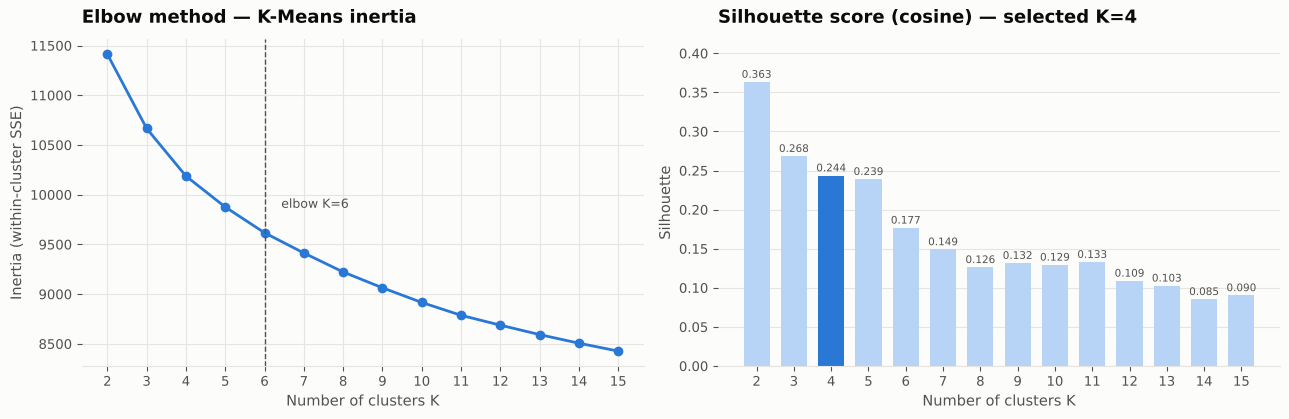

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(K_RANGE, inertias, color=viz.PRIMARY, lw=2, marker="o", ms=6)
axes[0].axvline(K_ELBOW, color=viz.INK2, ls="--", lw=1)
axes[0].annotate(f"elbow K={K_ELBOW}", (K_ELBOW, inertias[K_RANGE.index(K_ELBOW)]),
                 xytext=(12, 18), textcoords="offset points", color=viz.INK2, fontsize=9)
axes[0].set_title("Elbow method — K-Means inertia", loc="left")
axes[0].set_xlabel("Number of clusters K"); axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].set_xticks(K_RANGE)
bar_colors = [viz.CATEGORICAL[0] if k == K_BEST else "#b7d3f6" for k in K_RANGE]
axes[1].bar(K_RANGE, silhouettes, color=bar_colors, width=0.7, zorder=2)
for k, s in zip(K_RANGE, silhouettes):
    axes[1].text(k, s + max(silhouettes) * 0.015, f"{s:.3f}", ha="center", fontsize=7.5, color=viz.INK2)
axes[1].set_title(f"Silhouette score (cosine) — selected K={K_BEST}", loc="left")
axes[1].set_xlabel("Number of clusters K"); axes[1].set_ylabel("Silhouette"); axes[1].set_xticks(K_RANGE)
axes[1].set_ylim(0, max(silhouettes) * 1.15); axes[1].grid(axis="x", visible=False)
plt.tight_layout(); viz.save(fig, FIG, "09_elbow_silhouette"); plt.show()

In [29]:
kmeans = KMeans(n_clusters=K_BEST, n_init=10, random_state=SEED).fit(emb)
corpus["cluster"] = kmeans.labels_
sil_final = silhouette_score(emb[sil_idx], kmeans.labels_[sil_idx], metric="cosine")
ari = adjusted_rand_score(corpus[TARGET], corpus["cluster"])
nmi = normalized_mutual_info_score(corpus[TARGET], corpus["cluster"])
print(f"K={K_BEST}: silhouette={sil_final:.4f} | vs job_title_short (external, for interpretation only): "
      f"ARI={ari:.3f}, NMI={nmi:.3f}")

K=4: silhouette=0.2436 | vs job_title_short (external, for interpretation only): ARI=0.061, NMI=0.111


## 15a. Cluster interpretation and skill analysis

Cluster IDs are arbitrary: K-Means knows nothing about the categories. Each cluster is profiled from its **dominant job categories** and its **most frequent and most distinctive skills**. *Lift* is a skill's share inside the cluster divided by its share in the whole corpus. A readable label is then generated automatically from these statistics.

In [30]:
overall = Counter(s for lst in corpus["skills"] for s in lst)
N = len(corpus)
profiles = []
for c in range(K_BEST):
    sub = corpus[corpus["cluster"] == c]
    jt = sub[TARGET].value_counts(normalize=True)
    sc = Counter(s for lst in sub["skills"] for s in lst)
    top_freq = [(s, n / len(sub)) for s, n in sc.most_common(10)]
    lift = sorted(((s, (n / len(sub)) / (overall[s] / N)) for s, n in sc.items() if n / len(sub) >= 0.15),
                  key=lambda t: -t[1])
    fam = jt.index[0] if jt.iloc[0] >= 0.5 else f"{jt.index[0]} / {jt.index[1]}"
    distinct = [s for s, _ in lift[:3]] or [s for s, _ in top_freq[:3]]
    raw_titles = sub["job_title"].str.lower().value_counts().head(3)
    profiles.append({
        "cluster": c, "size": len(sub), "label": f"{fam} · {', '.join(distinct)}",
        "top_categories": [{"name": k, "share": float(v)} for k, v in jt.items()],
        "top_titles": [{"name": k, "count": int(v)} for k, v in raw_titles.items()],
        "top_skills": [{"name": s, "share": float(v)} for s, v in top_freq],
        "distinctive_skills": [{"name": s, "lift": float(v)} for s, v in lift[:6]],
        "purity": float(jt.iloc[0]),
    })
prof_df = pd.DataFrame([{
    "cluster": p["cluster"], "size": p["size"], "label": p["label"],
    "dominant categories": ", ".join(f"{d['name']} {d['share']:.0%}" for d in p["top_categories"][:3]),
    "most frequent skills": ", ".join(f"{d['name']} {d['share']:.0%}" for d in p["top_skills"][:6]),
} for p in profiles])
display(prof_df)
cluster_labels = {p["cluster"]: p["label"] for p in profiles}

,cluster,size,label,dominant categories,most frequent skills
0,0,5414,"Senior Data Engineer / Data Engineer · kafka, ...","Senior Data Engineer 17%, Data Engineer 16%, M...","python 80%, sql 58%, aws 47%, azure 37%, spark..."
1,1,3995,"Business Analyst / Data Analyst · excel, sql","Business Analyst 23%, Data Analyst 18%, Senior...","sql 29%, excel 28%, power bi 14%, tableau 13%,..."
2,2,2838,"Senior Data Analyst / Data Analyst · tableau, ...","Senior Data Analyst 24%, Data Analyst 19%, Bus...","sql 93%, python 61%, tableau 43%, excel 34%, r..."
3,3,2753,Machine Learning Engineer / Software Engineer ...,"Machine Learning Engineer 17%, Software Engine...","python 64%, sql 26%, aws 16%, r 15%, azure 12%..."


## 15b. Cluster visualisation

PCA projects the 768-d vectors onto the two directions of largest variance. UMAP is not used: it is not installed in this environment, and PCA is deterministic and *reusable*, so the app projects user queries onto the same plane. Each cluster has its own colour **and** its own marker shape, so identity never depends on colour alone. Centroids are marked with a ring and the cluster number, and the labels are placed so they do not overlap.

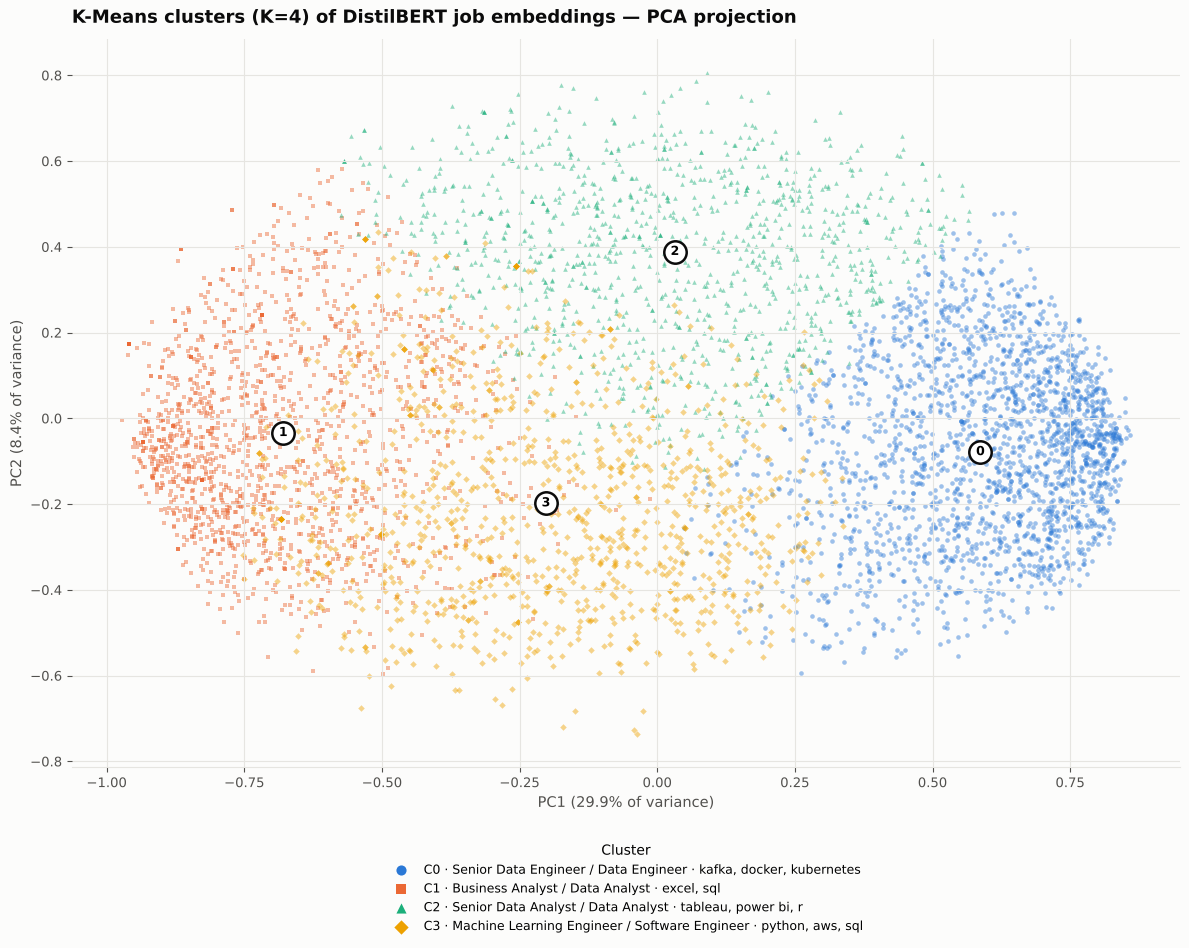

In [31]:
pca = PCA(n_components=2, random_state=SEED).fit(emb)
xy = pca.transform(emb)
cxy = pca.transform(kmeans.cluster_centers_)   # PCA is linear: this is the mean of the projected points
corpus["pca_x"], corpus["pca_y"] = xy[:, 0], xy[:, 1]
fig, ax = plt.subplots(figsize=(12, 9.6))
plot_idx = rng.choice(len(xy), 6000, replace=False)       # thin the cloud so each point is visible
for c in range(K_BEST):
    pts = plot_idx[corpus["cluster"].values[plot_idx] == c]
    ax.scatter(xy[pts, 0], xy[pts, 1], s=11, alpha=0.45, color=viz.cluster_color(c),
               marker=viz.cluster_marker(c), linewidths=0, label=f"C{c} · {cluster_labels[c]}")
for c in range(K_BEST):
    ax.scatter(*cxy[c], s=260, facecolor="white", edgecolor=viz.INK, linewidth=1.8, zorder=5)
    ax.text(*cxy[c], str(c), ha="center", va="center", fontsize=9, fontweight="bold", zorder=6)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
ax.set_title(f"K-Means clusters (K={K_BEST}) of DistilBERT job embeddings — PCA projection", loc="left")
leg = ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), markerscale=2.2, title="Cluster", fontsize=9,
                ncol=1 if K_BEST <= 6 else 2)
for lh in leg.legend_handles: lh.set_alpha(1)
plt.tight_layout(); viz.save(fig, FIG, "10_clusters_pca"); plt.show()

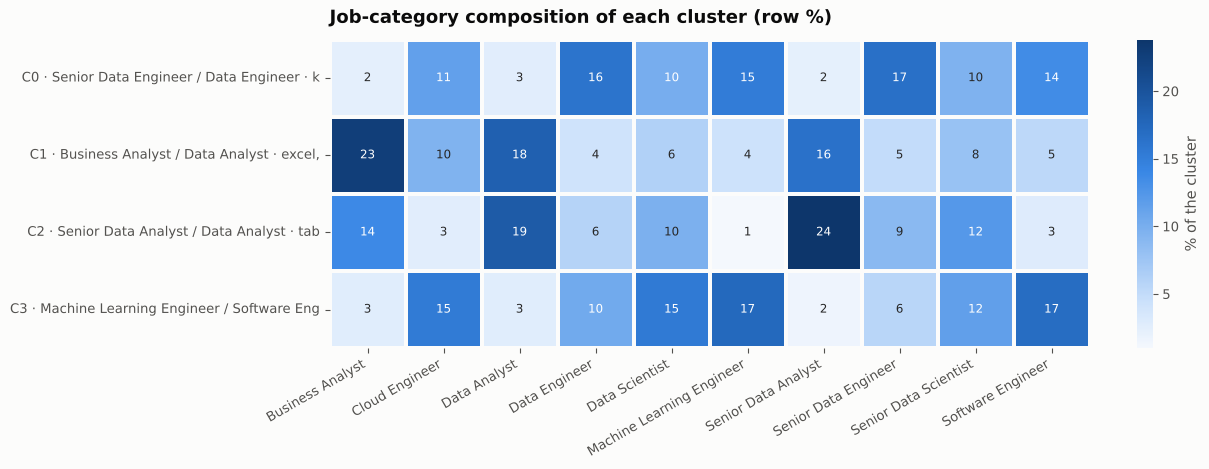

In [32]:
ct = pd.crosstab(corpus["cluster"], corpus[TARGET], normalize="index")
ct.index = [f"C{c} · {cluster_labels[c][:40]}" for c in ct.index]
fig, ax = plt.subplots(figsize=(13, 0.55 * K_BEST + 2.6))
sns.heatmap(ct * 100, annot=True, fmt=".0f", cmap=viz.SEQ_BLUE, linewidths=1.5, linecolor=viz.SURFACE,
            cbar_kws={"label": "% of the cluster"}, ax=ax, annot_kws={"fontsize": 8.5})
ax.set_title("Job-category composition of each cluster (row %)", loc="left"); ax.set_ylabel(""); ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right"); ax.grid(False)
plt.tight_layout(); viz.save(fig, FIG, "11_cluster_vs_category"); plt.show()

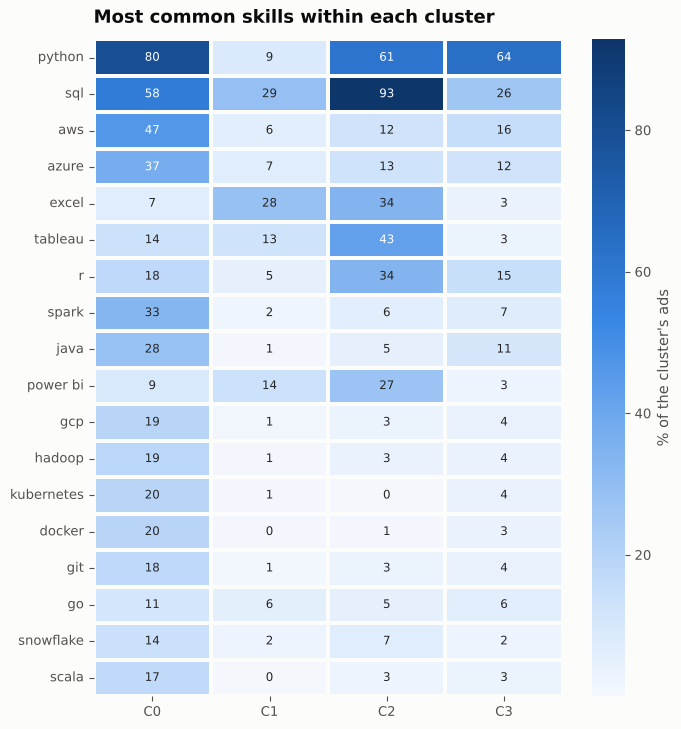

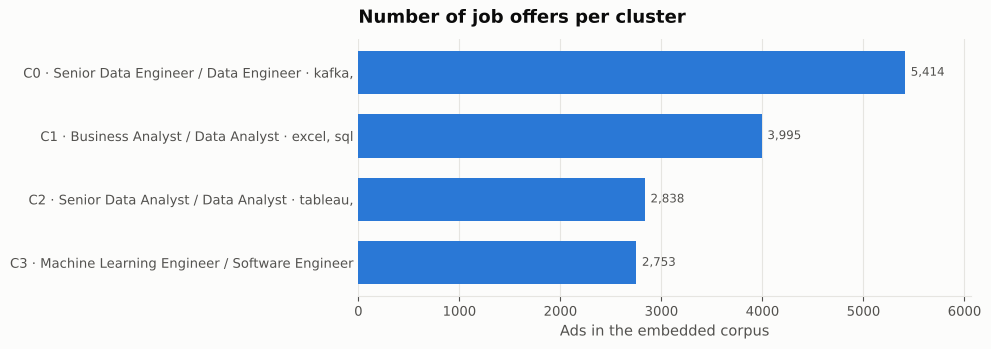

In [33]:
sk_top = [s for s, _ in overall.most_common(18)]
cs = pd.DataFrame({f"C{c}": [Counter(s for lst in corpus.loc[corpus.cluster == c, "skills"] for s in lst)[k] /
                             (corpus.cluster == c).sum() for k in sk_top] for c in range(K_BEST)}, index=sk_top)
fig, ax = plt.subplots(figsize=(0.75 * K_BEST + 4, 7.4))
sns.heatmap(cs * 100, annot=True, fmt=".0f", cmap=viz.SEQ_BLUE, linewidths=1.5, linecolor=viz.SURFACE,
            cbar_kws={"label": "% of the cluster's ads"}, ax=ax, annot_kws={"fontsize": 8.5})
ax.set_title("Most common skills within each cluster", loc="left"); ax.grid(False)
plt.tight_layout(); viz.save(fig, FIG, "12_skills_by_cluster"); plt.show()

sizes = corpus["cluster"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 0.45 * K_BEST + 1.8))
viz.hbar(ax, [f"C{c} · {cluster_labels[c][:45]}" for c in sizes.index], sizes.values.tolist(),
         "Number of job offers per cluster", "Ads in the embedded corpus")
plt.tight_layout(); viz.save(fig, FIG, "13_cluster_sizes"); plt.show()

**Cluster quality and interpretability.**
* **Choice of K.** The silhouette decreases almost monotonically with K, a classic pattern for dense language-model embeddings, whose ads form a continuum rather than well-separated blobs. The pre-declared rule picks the best K in [4, 12]. The elbow suggests a slightly larger K, which would split the families further, at the cost of a much lower silhouette. The clusters should be read as *regions* of the job market, not hard boundaries.
* **Interpretability.** Each cluster is a recognisable *professional family* (profile table, composition heatmap and skills heatmap above): data / big-data engineering (Python, cloud, Spark, Kafka), business analysis (Excel, SQL, Office tools), BI and analytics (SQL, Tableau, Python, R), and ML / software engineering (Python, deep-learning frameworks, general-purpose languages).
* **Not a copy of the categories.** The low ARI/NMI against `job_title_short` confirms that the clusters do not reproduce the official labels. The clearest example is seniority: Senior X and X ads of the same profession share clusters, because seniority is not a semantic dimension that DistilBERT separates. Analysts and business analysts are also regrouped by *tool stack* rather than by title.

In [34]:
# --- Save clustering artifacts ---
joblib.dump(kmeans, MODELS / "kmeans_model.joblib")
joblib.dump(pca, MODELS / "pca_2d.joblib")
corpus_out = corpus[["job_id", TARGET, "job_title", "company_name", "job_location", "job_country",
                     "skills_str", "salary_year_avg", "cluster", "pca_x", "pca_y"]]
corpus_out.to_csv(DATA_PROC / "embedding_corpus.csv", index=False)
clustering_config = {
    "representation": "DistilBERT mean-pooled embeddings, centered (corpus mean removed) and L2-normalised",
    "algorithm": "KMeans(n_init=10, k-means++)", "random_state": SEED, "k_range": K_RANGE,
    "inertia": inertias, "silhouette": silhouettes, "silhouette_sample": int(len(sil_idx)),
    "k_elbow": K_ELBOW, "k_selected": K_BEST,
    "selection_rule": "best cosine silhouette for K in [4,12]; elbow (Kneedle) as cross-check",
    "final_silhouette": float(sil_final), "ari_vs_job_title_short": float(ari), "nmi_vs_job_title_short": float(nmi),
    "pca_explained_variance": pca.explained_variance_ratio_.tolist(),
    "centroids_2d": cxy.tolist(), "profiles": profiles,
    "skills_by_cluster": {"skills": sk_top, "share": [cs[f"C{c}"].round(4).tolist() for c in range(K_BEST)]},
}
(MODELS / "clustering_config.json").write_text(json.dumps(clustering_config, indent=2))
(METRICS / "clustering_metrics.json").write_text(json.dumps({k: clustering_config[k] for k in
    ["k_range", "inertia", "silhouette", "k_elbow", "k_selected", "final_silhouette",
     "ari_vs_job_title_short", "nmi_vs_job_title_short"]}, indent=2))
print("saved kmeans_model.joblib, pca_2d.joblib, clustering_config.json, embedding_corpus.csv")

saved kmeans_model.joblib, pca_2d.joblib, clustering_config.json, embedding_corpus.csv


## 16. Knowledge graph: jobs – companies – skills

This section covers the graph part of the subject: a **tripartite graph**, **communities**, **skill recommendation** and a **mini question-answering system**.

* The whole cleaned dataset (564k ads) is compressed into a posting index: a sparse ad × skill matrix plus integer codes for company, category and country (`models/kg/`). Every graph and every answer is computed on demand from those real counts.
* **Nodes:** job categories, companies, skills. **Edges:** company *offers* job (number of ads), job *requires* skill (share of the job's ads), company *uses* skill (number of ads, top 3 per company to limit density).
* **Communities:** Louvain modularity maximisation (NetworkX).
* **Recommendation:** Personalised PageRank on the skill co-occurrence graph (edges = P(t | s) between positively associated skills), restarted on the seed skills and ranked by PPR × log(lift), so that the hub skills every job lists (Python, SQL) do not dominate. A trained GNN was not used because PyTorch / PyTorch-Geometric are unavailable; PPR is the classical non-parametric graph-propagation baseline for this task.
* **Q&A:** intent detection and entity linking (skills, job categories, countries), then a structured query on the graph and index, then a templated answer with an evidence table. Every number in an answer is a real count, and no text is generated by a language model.

In [35]:
kg_vocab = build_posting_index(df, MODELS / "kg")
kg = KnowledgeGraph(MODELS / "kg", extractor)
G = kg.build_graph(n_companies=25, n_skills=35)
communities = kg.detect_communities(G)
cy = kg.to_cytoscape(G, communities)
print("Default graph:", cy["stats"])
comm_tbl = pd.DataFrame([{"community": c, "members": ", ".join(sorted(G.nodes[n]["label"] for n in G.nodes if communities[n] == c)[:18])}
                         for c in sorted(set(communities.values()))])
display(comm_tbl)

Default graph: {'nodes': 63, 'edges': 286, 'communities': 4, 'modularity': 0.1887500611276835, 'by_type': {'job': 10, 'company': 25, 'skill': 28}}


,community,members
0,0,"Amazon, Capgemini, Capital One, Data Engineer,..."
1,1,"Accenture, Business Analyst, Citi, Confidenzia..."
2,2,"Booz Allen Hamilton, Data Scientist, Guidehous..."
3,3,"Cloud Engineer, Emprego, Software Engineer, Sy..."


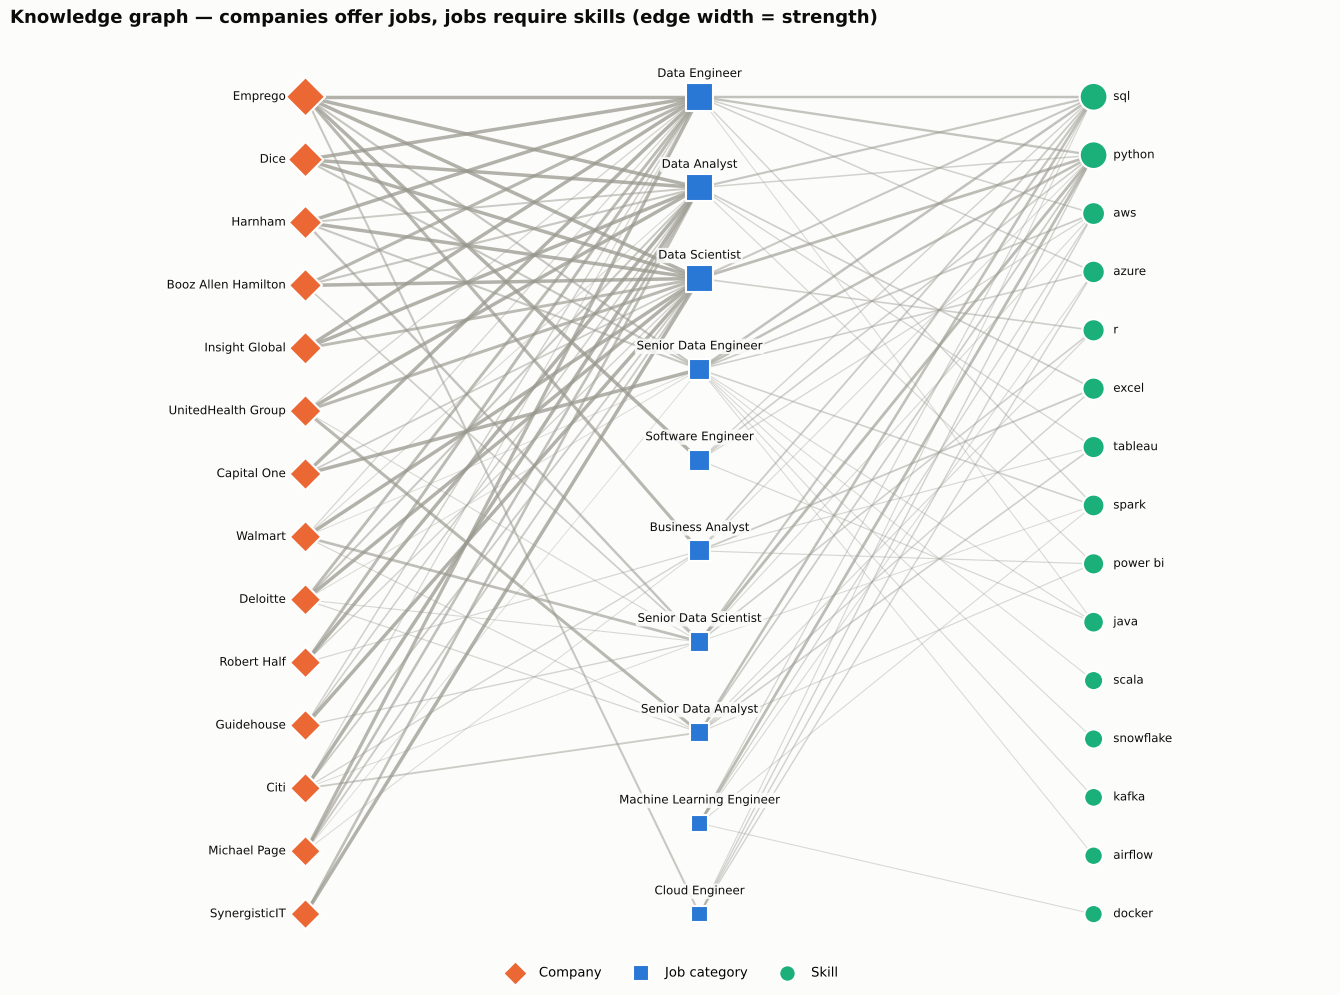

In [36]:
# Static view: a layered layout (companies | jobs | skills) avoids node overlap by construction
Gs = kg.build_graph(n_companies=14, n_skills=22, min_share=0.2, company_skill_k=0)
cols = {"company": 0.0, "job": 1.0, "skill": 2.0}
pos = {}
for t in cols:
    nodes = sorted([n for n, d in Gs.nodes(data=True) if d["type"] == t], key=lambda n: -Gs.nodes[n]["count"])
    ys = np.linspace(1, 0, len(nodes)) if len(nodes) > 1 else [0.5]
    for n, yv_ in zip(nodes, ys):
        pos[n] = (cols[t], yv_)
fig, ax = plt.subplots(figsize=(13.5, 10))
for u, v, d in Gs.edges(data=True):
    w = d["weight"] if d["type"] == "requires" else min(d["weight"] / 400, 1)
    ax.plot(*zip(pos[u], pos[v]), color="#9a998f", lw=0.3 + 2.2 * w, alpha=0.25 + 0.5 * w, zorder=1)
shape = {"company": "D", "job": "s", "skill": "o"}
for t in cols:
    nodes = [n for n in Gs if Gs.nodes[n]["type"] == t]
    cnt = np.array([Gs.nodes[n]["count"] for n in nodes], float)
    ax.scatter([pos[n][0] for n in nodes], [pos[n][1] for n in nodes], s=60 + 340 * np.sqrt(cnt / cnt.max()),
               color=viz.NODE_COLORS[t], marker=shape[t], edgecolor="white", linewidth=1.5, zorder=3,
               label={"company": "Company", "job": "Job category", "skill": "Skill"}[t])
    for n in nodes:
        ha, dx = ("right", -0.05) if t == "company" else (("left", 0.05) if t == "skill" else ("center", 0))
        dy = 0.028 if t == "job" else 0
        ax.text(pos[n][0] + dx, pos[n][1] + dy, Gs.nodes[n]["label"][:30], ha=ha, va="center", fontsize=8.5,
                color=viz.INK, zorder=4, bbox=dict(boxstyle="round,pad=0.15", fc=viz.SURFACE, ec="none", alpha=0.85))
ax.set_xlim(-0.75, 2.6); ax.set_ylim(-0.05, 1.07); ax.axis("off")
ax.set_title("Knowledge graph — companies offer jobs, jobs require skills (edge width = strength)", loc="left")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.04), ncol=3, markerscale=0.7)
plt.tight_layout(); viz.save(fig, FIG, "14_knowledge_graph_layered"); plt.show()

In [37]:
questions = [
    "Which companies offer jobs requiring Python and AWS?",
    "What skills does a Data Engineer need?",
    "Which jobs require Spark and Kafka?",
    "Which companies hire data scientists in France?",
    "Which skills should a data analyst who knows Excel and SQL learn next?",
    "What is the salary of a senior data scientist with PyTorch?",
]
qa_examples = []
for q in questions:
    a = kg.answer(q)
    qa_examples.append({"question": q, "answer": a["answer"], "parsed": a["parsed"]})
    display(Markdown(f"**Q:** {q}  \n**Parsed:** `{a['parsed']}`  \n**A:** {a['answer']}"))
    if a["table"]:
        display(pd.DataFrame(a["table"], columns=a["columns"]).head(6))

**Q:** Which companies offer jobs requiring Python and AWS?  
**Parsed:** `{'intent': 'companies', 'jobs': [], 'skills': ['python', 'aws'], 'country': None}`  
**A:** 91,928 postings match the query (requiring python + aws), from 28,620 companies. Top employers: Capital One (1403), Emprego (609), Dice (587), Harnham (518), Booz Allen Hamilton (507).

,Company,Matching postings,Share of matches
0,Capital One,1403,1.5%
1,Emprego,609,0.7%
2,Dice,587,0.6%
3,Harnham,518,0.6%
4,Booz Allen Hamilton,507,0.6%
5,Deloitte,370,0.4%


**Q:** What skills does a Data Engineer need?  
**Parsed:** `{'intent': 'skills', 'jobs': ['Data Engineer'], 'skills': [], 'country': None}`  
**A:** Across 143,773 postings (Data Engineer postings), the most requested skills are sql (67%), python (63%), aws (36%), azure (36%), spark (31%), java (21%).

,Skill,Category,Postings,Share
0,sql,Programming Languages,95836,66.7%
1,python,Programming Languages,90722,63.1%
2,aws,Cloud Platforms,52245,36.3%
3,azure,Cloud Platforms,51696,36.0%
4,spark,Data Engineering & Big Data,45078,31.4%
5,java,Programming Languages,29816,20.7%


**Q:** Which jobs require Spark and Kafka?  
**Parsed:** `{'intent': 'jobs', 'jobs': [], 'skills': ['spark', 'kafka'], 'country': None}`  
**A:** 28,995 postings match the query (requiring spark + kafka). They are mostly Data Engineer (61%), Senior Data Engineer (21%), Data Scientist (7%), Software Engineer (4%).

,Job category,Postings,Share of matches,Over-representation
0,Data Engineer,17600,60.7%,x2.38
1,Senior Data Engineer,6035,20.8%,x3.36
2,Data Scientist,2123,7.3%,x0.35
3,Software Engineer,1287,4.4%,x0.72
4,Data Analyst,580,2.0%,x0.08
5,Senior Data Scientist,501,1.7%,x0.37


... (2 outputs left out)

**Q:** Which skills should a data analyst who knows Excel and SQL learn next?  
**Parsed:** `{'intent': 'recommend', 'jobs': ['Data Analyst'], 'skills': ['excel', 'sql'], 'country': None}`  
**A:** Skills most connected to excel + sql in the graph (Personalised PageRank weighted by lift): powerpoint, tableau, power bi, word, vba, sas.

,Recommended skill,Category,Relevance (PPR x log-lift),Avg. co-occurrence,Lift
0,powerpoint,Data Analysis & Office Tools,0.0156,12.1%,x2.84
1,tableau,BI & Visualization Tools,0.0146,26.2%,x1.41
2,power bi,BI & Visualization Tools,0.0124,21.5%,x1.46
3,word,Data Analysis & Office Tools,0.0117,10.7%,x2.33
4,vba,Programming Languages,0.0054,4.6%,x2.47
5,sas,Data Analysis & Office Tools,0.0044,8.4%,x1.37


**Q:** What is the salary of a senior data scientist with PyTorch?  
**Parsed:** `{'intent': 'salary', 'jobs': ['Senior Data Scientist'], 'skills': ['pytorch'], 'country': None}`  
**A:** Median advertised yearly salary for Senior Data Scientist postings requiring pytorch: $157,500 (IQR $131,818-$175,000, based on the 170 postings that publish a salary, 4.8% of matches).

,Statistic,Yearly salary (USD)
0,Postings with salary,170
1,25th percentile,"131,818"
2,Median,"157,500"
3,75th percentile,"175,000"


In [38]:
(MODELS / "kg" / "default_graph.json").write_text(json.dumps(cy))
(MODELS / "kg" / "qa_examples.json").write_text(json.dumps(qa_examples, indent=2))
print("saved models/kg/ (posting index, vocabulary, default graph, Q&A examples)")

saved models/kg/ (posting index, vocabulary, default graph, Q&A examples)


## 17. Saving configurations and analytics; reload test in a separate process

In [39]:
(MODELS / "skill_extraction_config.json").write_text(json.dumps({**extractor.to_config(),
                                                                  "evaluation_on_titles": skill_eval}, indent=2))
(MODELS / "preprocessing_config.json").write_text(json.dumps({
    "source": "https://huggingface.co/datasets/lukebarousse/data_jobs", "raw_file": str(RAW_PATH.name),
    "kept_columns": KEEP_COLUMNS, "cleaning_report": clean_report,
    "text_tfidf": "clean_for_tfidf(job_title + ' | skills: ' + ', '.join(skills))",
    "text_embed": "job_title + '. Skills: ' + ', '.join(skills) + '.'",
    "near_duplicate_key": ["job_title", "company_name", "job_location", "skills"]}, indent=2))
(MODELS / "model_config.json").write_text(json.dumps({
    "distilbert": {"checkpoint": "distilbert-base-uncased", "source": "https://huggingface.co/distilbert-base-uncased",
                   "files": ["config.json", "vocab.txt", "model.safetensors"], "implementation": "jobnlp/distilbert.py (NumPy)",
                   "tokenizer": {"type": "WordPiece (uncased, strip accents)", "max_length": 128, "truncation": "head",
                                 "padding": "dynamic per batch", "batch_size": 64},
                   "pooling": "mean over attention-mask tokens", "normalisation": "L2; then corpus-mean centering + L2",
                   "embedding_dim": 768, "fine_tuned": False},
    "embeddings": {"file": "job_embeddings.npy (float16, raw L2-normalised)", "mean_file": "embedding_mean.npy",
                   "corpus_file": "data/processed/embedding_corpus.csv", "n": int(len(corpus)),
                   "sampling": "class-balanced, 1500 per job_title_short, random_state=42"},
    "classification": {"pipeline": "classification_pipeline.joblib", "input": "text_tfidf", "C": BEST_C,
                       "secondary": "skills_only_pipeline.joblib"},
    "clustering": {"model": "kmeans_model.joblib", "pca": "pca_2d.joblib", "k": K_BEST},
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__},
}, indent=2))

# Aggregated analytics for the dashboard - every value computed from the cleaned dataset
monthly_all = df.set_index("job_posted_date").resample("MS").size()
monthly_all = monthly_all[(monthly_all.index >= "2023-01-01") & (monthly_all.index < "2024-01-01")]
sal_stats = sal.groupby(TARGET)["salary_year_avg"].describe(percentiles=[.25, .5, .75])
analytics = {
    "totals": {"raw_postings": clean_report["raw_rows"], "postings": int(len(df)),
               "job_categories": int(df[TARGET].nunique()), "distinct_skills": int(len(skill_counter)),
               "companies": int(df["company_name"].nunique()), "countries": int(df["job_country"].nunique()),
               "clusters": int(K_BEST), "embedded_postings": int(len(corpus)),
               "remote_share": float(df["job_work_from_home"].mean())},
    "category_distribution": [{"name": k, "count": int(v)} for k, v in cat_counts.items()],
    "top_skills": [{"name": s, "count": int(c), "share": c / len(df), "category": extractor.skill2cat[s]}
                   for s, c in skill_counter.most_common(40)],
    "skills_by_category": {"skills": top_sk, "jobs": jobs_order,
                           "share": {j: share[j].round(4).tolist() for j in jobs_order}},
    "skill_category_mix": {"categories": cat_share.columns.tolist(),
                           "jobs": {j: cat_share.loc[j].round(4).tolist() for j in jobs_order}},
    "top_countries": [{"name": k, "count": int(v)} for k, v in df["job_country"].value_counts().head(15).items()],
    "monthly": [{"month": d.strftime("%Y-%m"), "count": int(v)} for d, v in monthly_all.items()],
    "salary_by_category": [{"name": j, "n": int(r["count"]), "q1": r["25%"], "median": r["50%"], "q3": r["75%"]}
                           for j, r in sal_stats.sort_values("50%").iterrows()],
    "schedule_types": [{"name": k, "count": int(v)} for k, v in df["job_schedule_type"].value_counts().head(6).items()],
    "skills_per_posting": {"median": float(df["n_skills"].median()), "mean": float(df["n_skills"].mean())},
    "skill_extraction_eval": skill_eval, "semantic_eval": sim_eval,
}
(MODELS / "analytics.json").write_text(json.dumps(analytics, indent=2, default=float))
print("saved model_config.json, preprocessing_config.json, skill_extraction_config.json, analytics.json")

saved model_config.json, preprocessing_config.json, skill_extraction_config.json, analytics.json


In [40]:
check = r'''
import sys, json, joblib, numpy as np
sys.path.insert(0, ROOT)
from pathlib import Path
M = Path(ROOT) / "models"
pipe = joblib.load(M / "classification_pipeline.joblib")
from jobnlp.preprocessing import clean_for_tfidf
print("classifier ->", pipe.predict([clean_for_tfidf("Senior Data Engineer | skills: spark, kafka, aws, python")])[0])
km = joblib.load(M / "kmeans_model.joblib"); emb = np.load(M / "job_embeddings.npy")
print("kmeans k =", km.n_clusters, "| embeddings", emb.shape, emb.dtype)
from jobnlp.graph import KnowledgeGraph
print("kg ->", KnowledgeGraph(M / "kg").answer("Which jobs require Tableau?")["answer"][:80])
'''.replace("ROOT", repr(str(PROJECT_ROOT)))
out = subprocess.run([sys.executable, "-c", check], capture_output=True, text=True, timeout=300)
print(out.stdout or out.stderr)
print("Artifacts in models/:")
for f in sorted(MODELS.rglob("*")):
    if f.is_file() and "distilbert" not in str(f.parent.name):
        print(f"  {str(f.relative_to(MODELS)):<40} {f.stat().st_size/1e6:7.2f} MB")

classifier -> Senior Data Engineer
kmeans k = 4 | embeddings (15000, 768) float16
kg -> 105,170 postings match the query (requiring tableau). They are mostly Data Analy

Artifacts in models/:
  analytics.json                              0.02 MB
  classification_pipeline.joblib              4.47 MB
  clustering_config.json                      0.01 MB
  embedding_mean.npy                          0.00 MB
  job_embeddings.meta.json                    0.00 MB
  job_embeddings.npy                         23.04 MB
  kg/default_graph.json                       0.06 MB
  kg/posting_skills.npz                       4.03 MB
  kg/postings.npz                             2.13 MB
  kg/qa_examples.json                         0.00 MB
  kg/vocab.json                               2.77 MB
  kmeans_model.joblib                         0.07 MB
  logistic_regression.joblib                  3.86 MB
  model_config.json                           0.00 MB
  pca_2d.joblib                               0.01 M

## 18. Results comparison and discussion

In [41]:
summary = pd.DataFrame([
    {"component": "Skill extraction (dictionary + rules)", "evaluation": "precision vs dataset tags on titles",
     "result": f"{skill_eval['precision_vs_tags']:.1%} on {skill_eval['extracted_mentions']:,} mentions"},
    {"component": "TF-IDF + LogReg (title + skills)", "evaluation": "test accuracy / macro-F1",
     "result": f"{results.loc['TF-IDF + LogReg (title + skills) - MAIN','accuracy']:.3f} / "
               f"{results.loc['TF-IDF + LogReg (title + skills) - MAIN','f1_macro']:.3f}"},
    {"component": "TF-IDF + LogReg (skills only)", "evaluation": "test accuracy / macro-F1",
     "result": f"{results.loc['TF-IDF + LogReg (skills only)','accuracy']:.3f} / "
               f"{results.loc['TF-IDF + LogReg (skills only)','f1_macro']:.3f}"},
    {"component": "DistilBERT semantic similarity", "evaluation": "label agreement@10 (semantic / TF-IDF / random)",
     "result": f"{sim_eval['label_agreement@10_semantic']:.3f} / {sim_eval['label_agreement@10_tfidf']:.3f} / "
               f"{sim_eval['random_baseline']:.3f}"},
    {"component": f"K-Means on DistilBERT (K={K_BEST})", "evaluation": "silhouette (cosine) / NMI vs categories",
     "result": f"{sil_final:.3f} / {nmi:.3f}"},
    {"component": "Knowledge graph", "evaluation": "nodes / edges / Louvain communities / modularity",
     "result": f"{cy['stats']['nodes']} / {cy['stats']['edges']} / {cy['stats']['communities']} / "
               f"{cy['stats']['modularity']:.3f}"},
])
display(summary)
summary.to_csv(METRICS / "results_summary.csv", index=False)

,component,evaluation,result
0,Skill extraction (dictionary + rules),precision vs dataset tags on titles,"92.2% on 58,234 mentions"
1,TF-IDF + LogReg (title + skills),test accuracy / macro-F1,0.949 / 0.918
2,TF-IDF + LogReg (skills only),test accuracy / macro-F1,0.515 / 0.236
3,DistilBERT semantic similarity,label agreement@10 (semantic / TF-IDF / random),0.480 / 0.473 / 0.100
4,K-Means on DistilBERT (K=4),silhouette (cosine) / NMI vs categories,0.244 / 0.111
5,Knowledge graph,nodes / edges / Louvain communities / modularity,63 / 286 / 4 / 0.189


**Discussion**

* **Supervised vs unsupervised.** TF-IDF + Logistic Regression is the right tool for *predicting the standard category*: it is fast (≈ 1 min on 450k ads), interpretable through its coefficients, and very accurate because category and title vocabulary are tightly linked. DistilBERT + K-Means answers a different question: *which professions resemble each other?* It finds families that cut across categories, for example BI-oriented analysts vs Python/ML analysts.
* **Keyword vs semantic.** TF-IDF needs shared words, while DistilBERT handles paraphrases. Its raw similarities are compressed and uncalibrated, and centering partly fixes this. A model fine-tuned for sentence similarity (e.g. Sentence-BERT, or DistilBERT fine-tuned with a contrastive loss on title/skill pairs) would be the next improvement.
* **Data limitation.** Because the dataset has no description text, the "job description" in this project is title + skills. The models accept any free text, and the app classifies pasted descriptions, but performance on long real descriptions is not measured here.
* **Graph.** The knowledge graph makes the skill ↔ job ↔ company relations explicit and supports exact, explainable answers. Recruiters and job boards (e.g. Dice, Harnham) appear as "companies", which is a known limitation of scraped job data.

## 19. Final conclusions

1. A complete pipeline was built and run on the **real** 785k-posting dataset: cleaning with leakage control, skill extraction, classification, semantic embeddings, clustering, a knowledge graph and Q&A.
2. The title + skills classifier predicts `job_title_short` with high accuracy and macro-F1 (Section 10). The skills-only model shows that the *skill profile* identifies the profession family but not the seniority.
3. DistilBERT embeddings, extracted with mean pooling from the official checkpoint and implemented and validated in NumPy, enable semantic search that works beyond keyword overlap.
4. K-Means on these embeddings, with K chosen by silhouette and elbow, discovers interpretable professional families, each with a characteristic skill set.
5. All artifacts are saved in reusable formats (joblib, npy, json) and are loaded by the Flask application without retraining.